In [28]:
import anndata as ad
import os
spatial_dir = '/work/magroup/skrieger/Syndri/data/datasets/agingbrain_merfish/results/final/'

files = sorted([f for f in os.listdir(spatial_dir) if f.endswith('.h5ad')])

adata = ad.concat([ad.read_h5ad(os.path.join(spatial_dir,f)) for f in files])
# ad.read_h5ad('/work/magroup/skrieger/Syndri/data/datasets/agingbrain_merfish/results/final/')

In [29]:
adata.obs['cell_type'].unique()

['inhibitory interneuron', 'neuron', 'astrocyte', 'pericyte', 'oligodendrocyte precursor cell', ..., 'medium spiny neuron', 'macrophage', 'T cell', 'vascular leptomeningeal cell', 'cell']
Length: 13
Categories (13, object): ['cell', 'T cell', 'endothelial cell', 'astrocyte', ..., 'pericyte', 'oligodendrocyte precursor cell', 'medium spiny neuron', 'vascular leptomeningeal cell']

In [30]:
# UMI counts <2500
adata = adata[adata.X.sum(axis=1)<2500]
# adata = adata[(adata.X>0).sum(axis=1)<1000]

### Activation scores by age

In [31]:
import pandas as pd
gene_map = pd.read_csv('ABMERFISH_genemap.csv')

gene_map['cell_type'] = 'astrocyte'
gene_map.loc[gene_map.index[8:-3], 'cell_type'] = 'microglial cell'
gene_map.loc[gene_map.index[-3:], 'cell_type'] = 'oligodendrocyte'
gene_map

,initial_alias,converted_alias,name,description,namespace,cell_type
0,C4B,ENSMUSG00000073418,C4b,complement C4B (Chido blood group) [Source:MGI...,"ENTREZGENE,MGI,UNIPROT_GN,WIKIGENE",astrocyte
1,C3,ENSMUSG00000024164,C3,complement component 3 [Source:MGI Symbol;Acc:...,"ENTREZGENE,MGI,UNIPROT_GN,WIKIGENE",astrocyte
2,SERPINA3N,ENSMUSG00000021091,Serpina3n,"serine (or cysteine) peptidase inhibitor, clad...","ENTREZGENE,MGI,UNIPROT_GN,WIKIGENE",astrocyte
3,CXCL10,ENSMUSG00000034855,Cxcl10,C-X-C motif chemokine ligand 10 [Source:MGI Sy...,"ENTREZGENE,MGI,UNIPROT_GN,WIKIGENE",astrocyte
4,GFAP,ENSMUSG00000020932,Gfap,glial fibrillary acidic protein [Source:MGI Sy...,"ENTREZGENE,MGI,UNIPROT_GN,WIKIGENE",astrocyte
5,VIM,ENSMUSG00000026728,Vim,vimentin [Source:MGI Symbol;Acc:MGI:98932],"ENTREZGENE,MGI,UNIPROT_GN,WIKIGENE",astrocyte
6,IL18,ENSMUSG00000039217,Il18,interleukin 18 [Source:MGI Symbol;Acc:MGI:107936],"ENTREZGENE,MGI,UNIPROT_GN,WIKIGENE",astrocyte
7,HIF3A,ENSMUSG00000004328,Hif3a,"hypoxia inducible factor 3, alpha subunit [Sou...","ENTREZGENE,MGI,UNIPROT_GN,WIKIGENE",astrocyte
8,B2M,ENSMUSG00000060802,B2m,beta-2 microglobulin [Source:MGI Symbol;Acc:MG...,"ENTREZGENE,MGI,UNIPROT_GN,WIKIGENE",microglial cell
9,TREM2,ENSMUSG00000023992,Trem2,triggering receptor expressed on myeloid cells...,"ENTREZGENE,MGI,UNIPROT_GN,WIKIGENE",microglial cell


In [32]:
tissue_names = sorted(adata.obs['tissue'].unique())
aliases = ['Ventricle','Corpus\nCallosum','L2/3','L5','L6','Olf','Pia','Striatum']
adata.obs['tissue_short'] = adata.obs['tissue'].map(dict(zip(tissue_names,aliases)))
import scanpy as sc 
cell_types = ['astrocyte','microglial cell','oligodendrocyte']
ct_adatas = []
for ct in cell_types:
    ct_adata = adata[adata.obs['cell_type']==ct].copy()
    sc.pp.normalize_total(ct_adata,target_sum=10000)
    sc.pp.log1p(ct_adata)
    sc.pp.scale(ct_adata)
    gene_list = sorted(gene_map[gene_map['cell_type']==ct]['converted_alias'].unique())
    sc.tl.score_genes(ct_adata,gene_list)
    ct_adatas.append(ct_adata)
# sc.tl.score_genes()

/tmp/ipykernel_3674961/891122450.py:3: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['tissue_short'] = adata.obs['tissue'].map(dict(zip(tissue_names,aliases)))


In [33]:
adata.obs['clust_annot'].unique()

['InN-Pvalb-1', 'ExN-L5-1', 'ExN-L2/3-2', 'Astro-1', 'Peri-1', ..., 'InN-Olf-2', 'InN-Chat', 'InN-Calb2-2', 'Epen', 'InN-Pvalb-2']
Length: 43
Categories (43, object): ['Astro-1', 'Astro-2', 'Endo-1', 'Endo-2', ..., 'Peri-1', 'Peri-2', 'T cell', 'Vlmc']

/tmp/ipykernel_3674961/796396247.py:7: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=ct_adatas[i].obs,x='tissue_short',y='score',hue='age',color='black',dodge=True,alpha=0.2,s=2,ax=ax,legend=False,order=tissue_order)
/tmp/ipykernel_3674961/796396247.py:7: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=ct_adatas[i].obs,x='tissue_short',y='score',hue='age',color='black',dodge=True,alpha=0.2,s=2,ax=ax,legend=False,order=tissue_order)
/tmp/ipykernel_3674961/796396247.py:7: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=ct_adatas[i].obs,x='tissue_short',y='score',hue='age',color='black',dodge=True,alpha=0.2,s=2,ax=ax,l

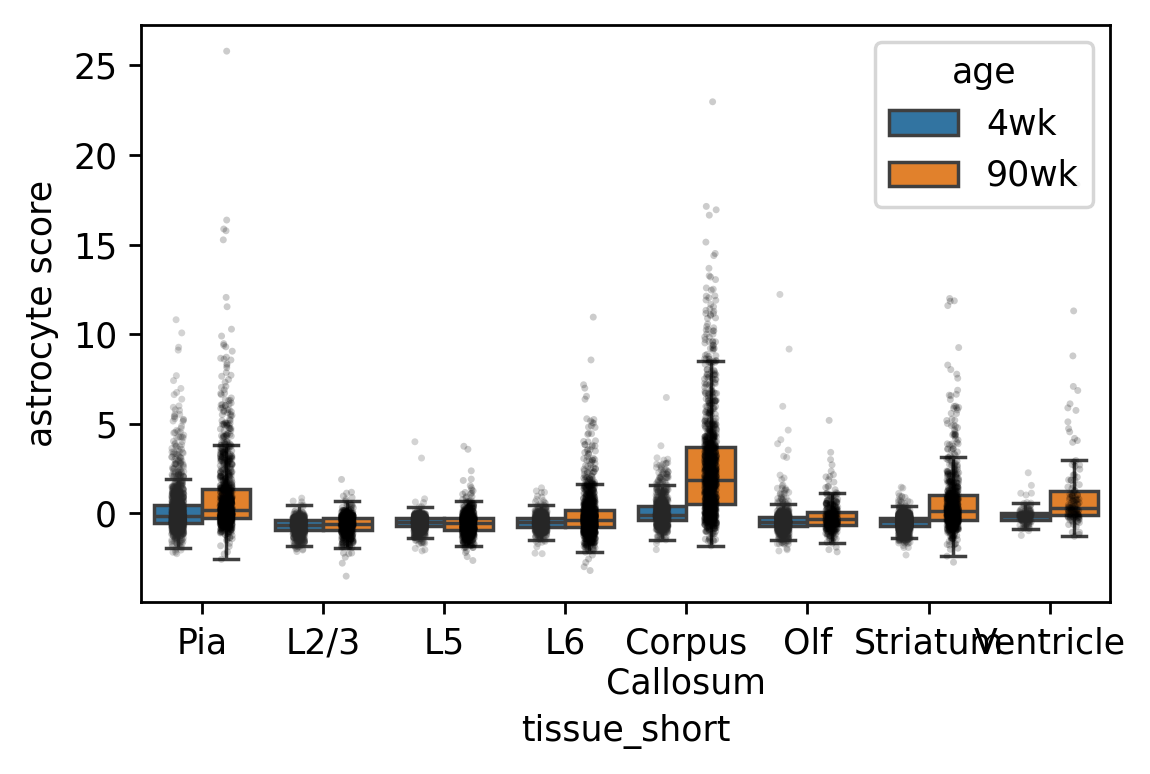

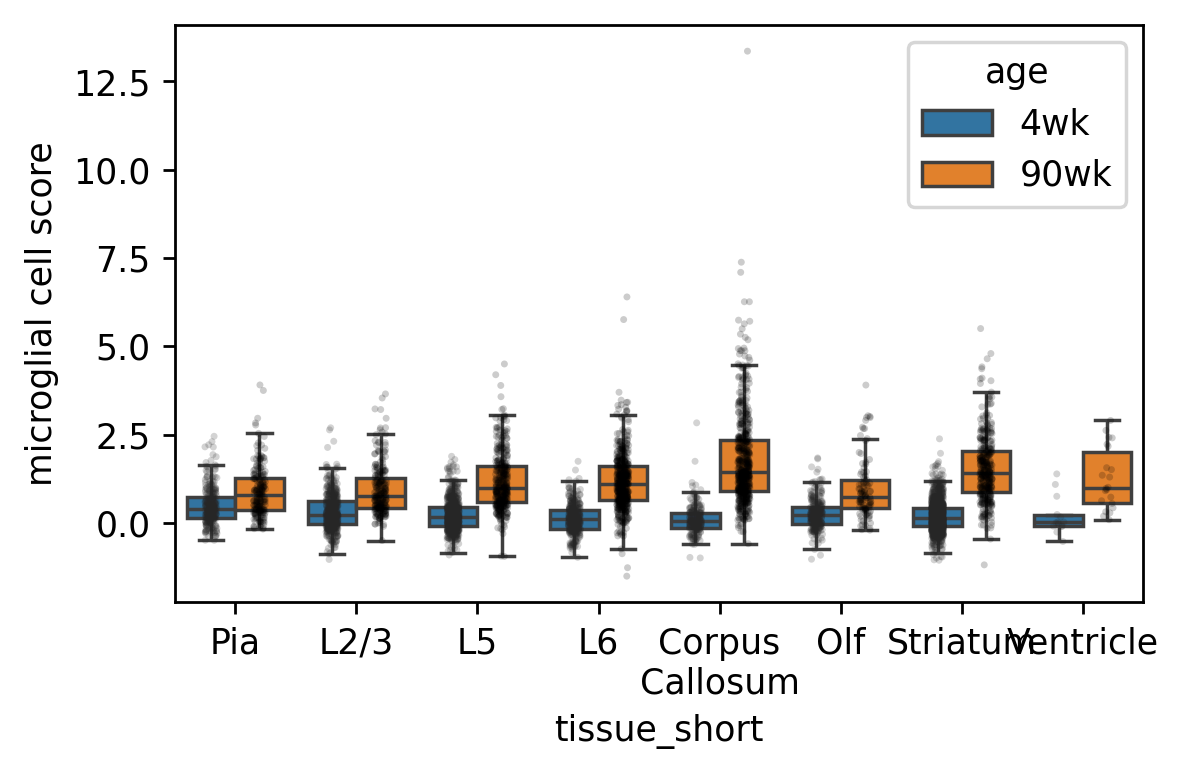

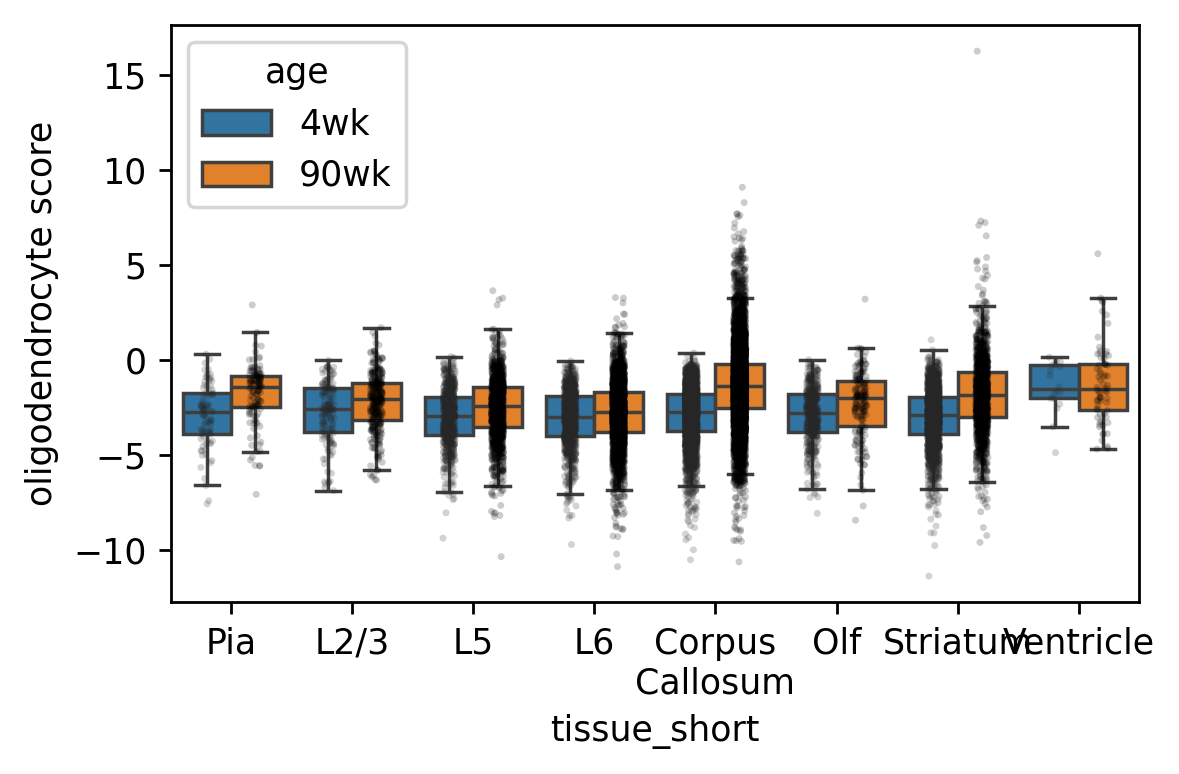

In [34]:
import seaborn as sns
import matplotlib.pyplot as plt
tissue_order = ["Pia","L2/3","L5","L6","Corpus\nCallosum","Olf","Striatum","Ventricle"]
for i,ct in enumerate(cell_types):
    fig,ax = plt.subplots(figsize=(5,3),dpi=250)
    sns.boxplot(data=ct_adatas[i].obs,x='tissue_short',y='score',hue='age',showfliers=False,ax=ax,order=tissue_order)
    sns.stripplot(data=ct_adatas[i].obs,x='tissue_short',y='score',hue='age',color='black',dodge=True,alpha=0.2,s=2,ax=ax,legend=False,order=tissue_order)
    ax.set_ylabel(f'{ct} score')

## Aging-associated activation-score changes by method

For each gene-set score and cell type, this compares the oldest and youngest ages within each tissue region. Cells are first averaged within each slice, then slice means are averaged within age, so slices contribute equally. The three model inputs use the regenerated runs referenced in `eval/AllDatasetMetricsSimplified.ipynb`: Syndri milestone 87, regenerated ResolVI, and regenerated SPLIT. ResolVI and SPLIT use their cleaned-count layers; Syndri’s 10% cleaned counts are reconstructed from its probability layer using the same settings as the evaluation notebook. The first heatmap column shows \(\Delta_{\mathrm{aging}} = \mathrm{mean}(score_{oldest}) - \mathrm{mean}(score_{youngest})\). The second shows each method’s \(\Delta_{\mathrm{aging}}\) minus Syndri’s for the same cell type and region, making method differences explicit.

/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/functools.py:889: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/functools.py:889: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/functools.py:889: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/functools.py:889: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/functools.py:889: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/functools.py:889: UserWarning: zer

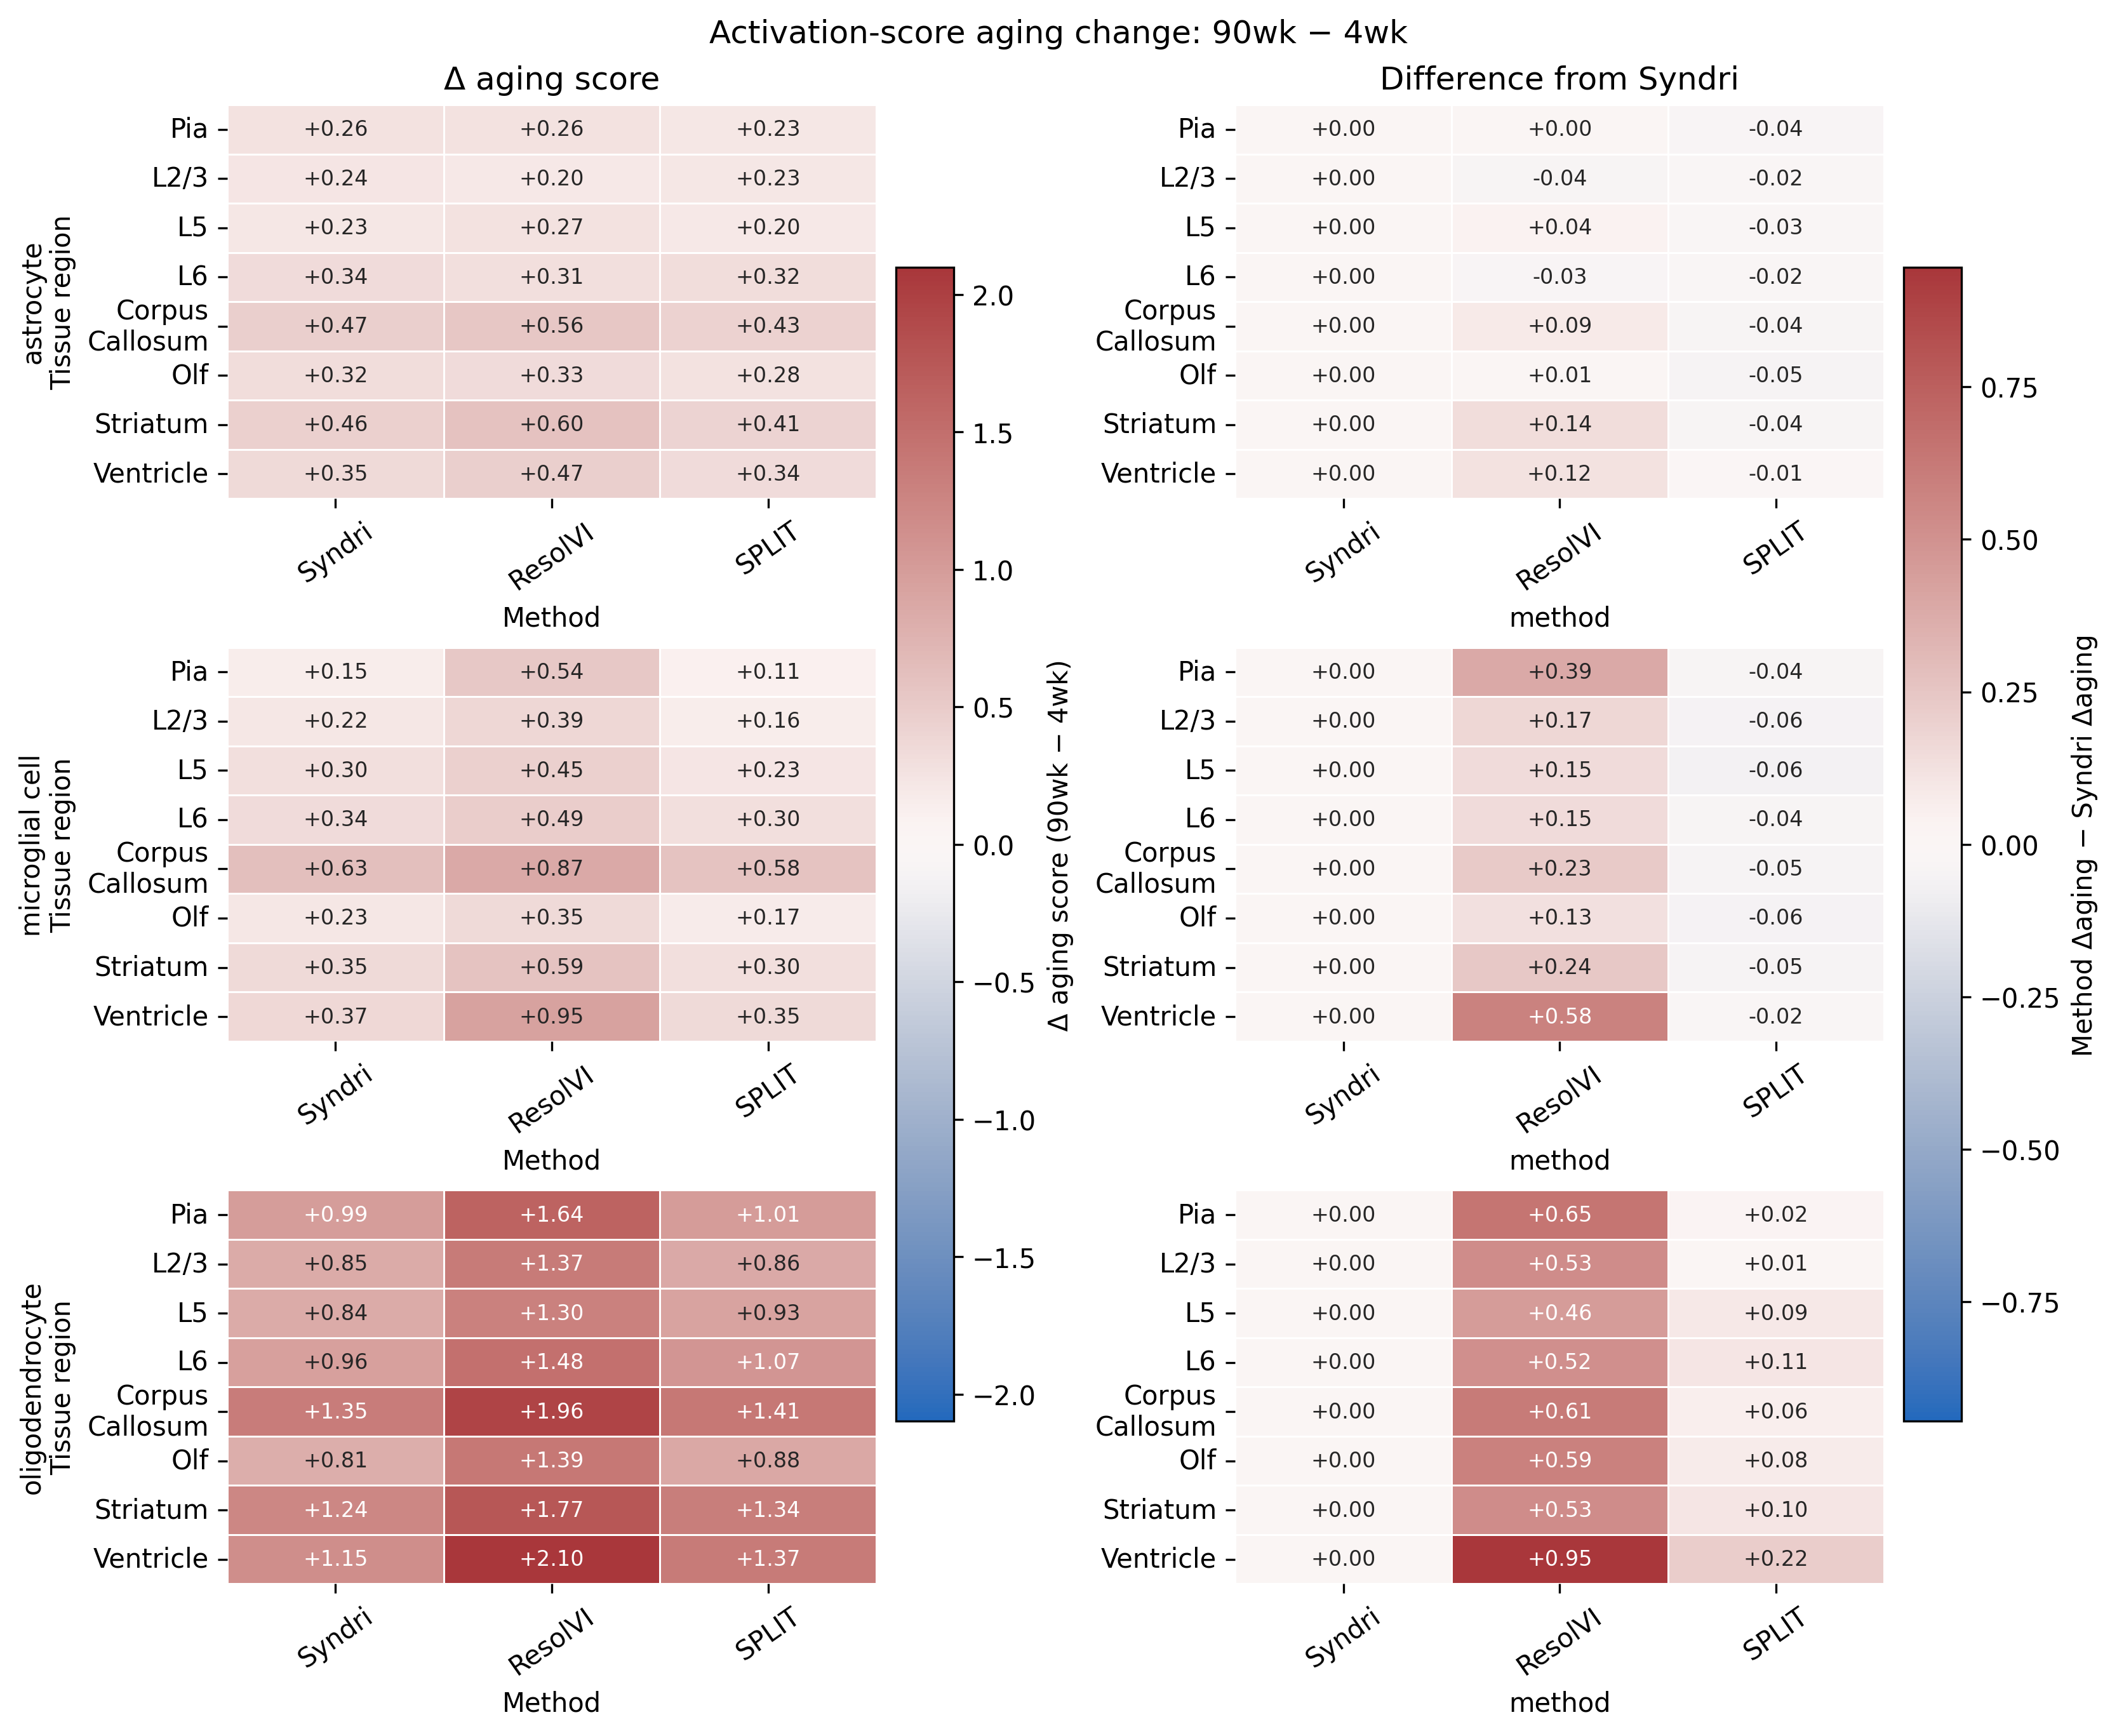

,method,cell_type,tissue,youngest_age,oldest_age,youngest_mean,oldest_mean,n_youngest_slices,n_oldest_slices,delta_aging
0,ResolVI,astrocyte,Corpus\nCallosum,4wk,90wk,0.058864,0.616158,6,6,0.557294
1,SPLIT,astrocyte,Corpus\nCallosum,4wk,90wk,0.015057,0.444734,6,6,0.429676
2,Syndri,astrocyte,Corpus\nCallosum,4wk,90wk,0.002258,0.472105,6,6,0.469847
3,ResolVI,astrocyte,L2/3,4wk,90wk,-0.387585,-0.188431,6,6,0.199154
4,SPLIT,astrocyte,L2/3,4wk,90wk,-0.279400,-0.053133,6,6,0.226267
...,...,...,...,...,...,...,...,...,...,...
67,SPLIT,oligodendrocyte,Striatum,4wk,90wk,-0.766119,0.576398,6,6,1.342518
68,Syndri,oligodendrocyte,Striatum,4wk,90wk,-0.740634,0.498360,6,6,1.238994
69,ResolVI,oligodendrocyte,Ventricle,4wk,90wk,-1.262217,0.836279,5,4,2.098496
70,SPLIT,oligodendrocyte,Ventricle,4wk,90wk,-0.759729,0.614076,5,4,1.373805


In [35]:
from pathlib import Path
import re
import sys
import argparse
import anndata as ad
import scanpy as sc
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# These are the regenerated MERFISH outputs used by the evaluation notebook.
AGING_RESULTS = Path('/work/magroup/skrieger/Syndri/data/datasets/agingbrain_merfish/results')
AGING_METHOD_FILES = {
    'Syndri': sorted((AGING_RESULTS / 'model_runs' / '10x_agingbrain_donors5to8_m87_regenerated_rctd_20261010').glob('*.h5ad')),
    'ResolVI': sorted((AGING_RESULTS / 'competitors' / 'regenerated_interim' / 'resolvi').glob('*.h5ad')),
    'SPLIT': sorted((AGING_RESULTS / 'split' / 'regenerated_rctd_20261010' / 'merged_h5ad').glob('*.h5ad')),
}
CLEANED_EXPRESSION_LAYERS = {
    'ResolVI': 'resolvi_corrected_counts',
    'SPLIT': 'split_purified_counts_X',
}
if any(not paths for paths in AGING_METHOD_FILES.values()):
    missing = [method for method, paths in AGING_METHOD_FILES.items() if not paths]
    raise FileNotFoundError(f'Missing regenerated h5ad inputs for: {missing}')

# The evaluator selects Syndri's 10% fixed-removal condition from X plus its
# probability layer. SPLIT and ResolVI already store their cleaned matrices in
# method-specific layers. These are the metric run's documented settings.
sys.path.insert(0, '/home/jwinchel/Syndri/eval')
from metrics_eval import cleaned_counts_for_removed_fraction_maybe_grouped
SYNDRI_TARGET_FRACTION = 0.1
syndri_cleaning_args = argparse.Namespace(
    cleaning_mode='zero',
    cell_type_specific_removal=True,
    probability_transform='power',
    probability_power=2.0,
    clean_prob_threshold=0.5,
    tcell_probability_removal_scale=1.0,
)

# Load method-specific cleaned expression, then keep the <2500 UMI filter
# used by the original Figure 4 activation-score analysis.
method_adatas = []
for method, paths in AGING_METHOD_FILES.items():
    parts = []
    for path in paths:
        part = ad.read_h5ad(path)
        if method == 'Syndri':
            required = {'syndri_admix_probs_X'}
            missing = required - set(part.layers.keys())
            if missing:
                raise KeyError(f'{path} is missing Syndri probability layer(s): {sorted(missing)}')
            cleaned, *_ = cleaned_counts_for_removed_fraction_maybe_grouped(
                part.X,
                part.layers['syndri_admix_probs_X'],
                SYNDRI_TARGET_FRACTION,
                syndri_cleaning_args,
                labels=part.obs['cell_type'],
            )
            part.X = cleaned
        else:
            layer = CLEANED_EXPRESSION_LAYERS[method]
            if layer not in part.layers:
                raise KeyError(f'{path} is missing cleaned expression layer {layer!r}')
            part.X = part.layers[layer].copy()
        part.obs['slice'] = path.stem
        part.obs['method'] = method
        parts.append(part)
    method_adata = ad.concat(parts, join='inner', merge='same')
    method_adata = method_adata[method_adata.X.sum(axis=1) < 2500].copy()
    method_adatas.append(method_adata)

# Use the same tissue aliases, cell types, gene sets, and score preprocessing
# as the existing activation-score panels above.
tissue_names = sorted(method_adatas[0].obs['tissue'].dropna().unique())
tissue_aliases = ['Ventricle', 'Corpus\nCallosum', 'L2/3', 'L5', 'L6', 'Olf', 'Pia', 'Striatum']
tissue_map = dict(zip(tissue_names, tissue_aliases))
tissue_order = ['Pia', 'L2/3', 'L5', 'L6', 'Corpus\nCallosum', 'Olf', 'Striatum', 'Ventricle']
cell_types = ['astrocyte', 'microglial cell', 'oligodendrocyte']

aging_slice_rows = []
resolvi_cell_score_rows = []
proximity_score_rows = []
proximity_reference_rows = []
for method_adata in method_adatas:
    method = method_adata.obs['method'].iloc[0]
    method_adata.obs['tissue_short'] = method_adata.obs['tissue'].map(tissue_map)
    coordinate_cols = ['center_x', 'center_y']
    missing_coordinate_cols = set(coordinate_cols) - set(method_adata.obs.columns)
    if missing_coordinate_cols:
        raise KeyError(f'Missing spatial centroid columns: {sorted(missing_coordinate_cols)}')
    reference_obs = method_adata.obs[['slice', 'age', 'cell_type', *coordinate_cols]].copy()
    reference_obs['method'] = method
    for coordinate in coordinate_cols:
        reference_obs[coordinate] = pd.to_numeric(reference_obs[coordinate].astype(str), errors='coerce')
    proximity_reference_rows.append(reference_obs.dropna(subset=coordinate_cols))
    for cell_type in cell_types:
        ct_adata = method_adata[method_adata.obs['cell_type'].eq(cell_type)].copy()
        sc.pp.normalize_total(ct_adata, target_sum=10000)
        sc.pp.log1p(ct_adata)
        sc.pp.scale(ct_adata)
        gene_list = sorted(gene_map.loc[gene_map['cell_type'].eq(cell_type), 'converted_alias'].dropna().unique())
        score_genes = [gene for gene in gene_list if gene in ct_adata.var_names]
        if not score_genes:
            raise ValueError(f'No activation genes found in {method} {cell_type} data')
        sc.tl.score_genes(ct_adata, score_genes, score_name='score', use_raw=False)
        if cell_type in ['astrocyte', 'microglial cell', 'oligodendrocyte']:
            proximity_obs = ct_adata.obs[['slice', 'age', 'tissue_short', 'cell_type', 'score', *coordinate_cols]].copy()
            proximity_obs['method'] = method
            for coordinate in coordinate_cols:
                proximity_obs[coordinate] = pd.to_numeric(proximity_obs[coordinate].astype(str), errors='coerce')
            proximity_score_rows.append(proximity_obs.dropna(subset=['score', *coordinate_cols]))
        if method == 'ResolVI':
            score_obs = ct_adata.obs[['slice', 'age', 'tissue_short', 'score']].copy()
            score_obs['cell_type'] = cell_type
            resolvi_cell_score_rows.append(score_obs)
        slice_means = (
            ct_adata.obs.groupby(['slice', 'age', 'tissue_short'], observed=True)['score']
            .mean().rename('score').reset_index()
        )
        slice_means['method'] = method
        slice_means['cell_type'] = cell_type
        aging_slice_rows.append(slice_means)

aging_slice_scores = pd.concat(aging_slice_rows, ignore_index=True)
resolvi_cell_scores = pd.concat(resolvi_cell_score_rows, ignore_index=True)
proximity_scores = pd.concat(proximity_score_rows, ignore_index=True)
proximity_reference_cells = pd.concat(proximity_reference_rows, ignore_index=True)

# Score the original, uncleaned counts once as a shared Raw baseline. The
# Syndri AnnData retains those counts in .raw while .X contains cleaned counts.
raw_source = next(adata for adata in method_adatas if adata.obs['method'].iloc[0] == 'Syndri')
if raw_source.raw is None:
    raise ValueError('Syndri input has no .raw matrix for the uncleaned Raw variance baseline')
raw_adata = raw_source.raw.to_adata()
raw_adata.obs = raw_source.obs.copy()
raw_variance_score_rows = []
for cell_type in cell_types:
    raw_ct_adata = raw_adata[raw_adata.obs['cell_type'].eq(cell_type)].copy()
    sc.pp.normalize_total(raw_ct_adata, target_sum=10000)
    sc.pp.log1p(raw_ct_adata)
    sc.pp.scale(raw_ct_adata)
    raw_gene_list = sorted(
        gene_map.loc[gene_map['cell_type'].eq(cell_type), 'converted_alias'].dropna().unique()
    )
    raw_score_genes = [gene for gene in raw_gene_list if gene in raw_ct_adata.var_names]
    if not raw_score_genes:
        raise ValueError(f'No raw scoring genes found for {cell_type}')
    sc.tl.score_genes(raw_ct_adata, raw_score_genes, score_name='score', use_raw=False)
    raw_score_obs = raw_ct_adata.obs[
        ['slice', 'age', 'tissue_short', 'cell_type', 'score']
    ].copy()
    raw_score_obs['method'] = 'Raw'
    raw_variance_score_rows.append(raw_score_obs)
raw_proximity_scores = pd.concat(raw_variance_score_rows, ignore_index=True)
variance_scores = pd.concat([raw_proximity_scores, proximity_scores], ignore_index=True)

# Infer chronological age ordering from numeric labels (for example, months).
# If labels are nonnumeric, use their declared categorical order or sorted order.
age_values = aging_slice_scores['age'].dropna().unique().tolist()
def age_key(value):
    match = re.search(r'\d+(?:\.\d+)?', str(value))
    return (0, float(match.group())) if match else (1, str(value).lower())
if isinstance(aging_slice_scores['age'].dtype, pd.CategoricalDtype) and aging_slice_scores['age'].cat.ordered:
    age_order = [value for value in aging_slice_scores['age'].cat.categories if value in age_values]
else:
    age_order = sorted(age_values, key=age_key)
if len(age_order) < 2:
    raise ValueError(f'Need at least two ages to calculate an aging difference; found {age_order}')
youngest_age, oldest_age = age_order[0], age_order[-1]

age_slice_means = (
    aging_slice_scores.groupby(['method', 'cell_type', 'tissue_short', 'age'], observed=True)
    .agg(mean_score=('score', 'mean'), n_slices=('slice', 'nunique'))
    .reset_index()
)
aging_delta_rows = []
for (method, cell_type, tissue), subset in age_slice_means.groupby(['method', 'cell_type', 'tissue_short'], observed=True):
    by_age = subset.set_index('age')
    if youngest_age not in by_age.index or oldest_age not in by_age.index:
        continue
    aging_delta_rows.append({
        'method': method,
        'cell_type': cell_type,
        'tissue': tissue,
        'youngest_age': youngest_age,
        'oldest_age': oldest_age,
        'youngest_mean': by_age.loc[youngest_age, 'mean_score'],
        'oldest_mean': by_age.loc[oldest_age, 'mean_score'],
        'n_youngest_slices': by_age.loc[youngest_age, 'n_slices'],
        'n_oldest_slices': by_age.loc[oldest_age, 'n_slices'],
        'delta_aging': by_age.loc[oldest_age, 'mean_score'] - by_age.loc[youngest_age, 'mean_score'],
    })
aging_delta = pd.DataFrame(aging_delta_rows)

# Show both the age effect and the direct difference from Syndri. Each column
# uses one shared, zero-centered scale across cell types.
method_order = ['Syndri', 'ResolVI', 'SPLIT']
aging_limit = np.nanmax(np.abs(aging_delta['delta_aging']))
aging_limit = max(aging_limit, 1e-8)
contrast_rows = []
fig, axes = plt.subplots(3, 2, figsize=(11, 9), dpi=300, constrained_layout=True)
aging_mesh = None
contrast_mesh = None
for row, cell_type in enumerate(cell_types):
    heat = (
        aging_delta.loc[aging_delta['cell_type'].eq(cell_type)]
        .pivot(index='tissue', columns='method', values='delta_aging')
        .reindex(index=tissue_order, columns=method_order)
    )
    contrast = heat.subtract(heat['Syndri'], axis=0)
    contrast_rows.extend(
        contrast.rename_axis(index='tissue', columns='method')
        .stack(dropna=False).rename('delta_aging_vs_syndri').reset_index()
        .assign(cell_type=cell_type).to_dict('records')
    )

    aging_annotations = heat.applymap(lambda value: f'{value:+.2f}' if pd.notna(value) else '')
    aging_mesh = sns.heatmap(
        heat, mask=heat.isna(), annot=aging_annotations, fmt='', cmap='vlag', center=0,
        vmin=-aging_limit, vmax=aging_limit, linewidths=0.6, linecolor='white',
        cbar=False, annot_kws={'fontsize': 8}, ax=axes[row, 0],
    )
    axes[row, 0].set_ylabel(f'{cell_type}\nTissue region')
    axes[row, 0].set_xlabel('Method')
    axes[row, 1].set_ylabel('')
    axes[row, 1].set_xlabel('Method')
    for ax in axes[row]:
        ax.tick_params(axis='x', rotation=35)
        ax.tick_params(axis='y', rotation=0)

# Replot the contrast column using one shared limit so differences are comparable.
contrast_df = pd.DataFrame(contrast_rows)
contrast_limit = max(float(np.nanmax(np.abs(contrast_df['delta_aging_vs_syndri']))), 1e-8)
for row, cell_type in enumerate(cell_types):
    heat = (
        aging_delta.loc[aging_delta['cell_type'].eq(cell_type)]
        .pivot(index='tissue', columns='method', values='delta_aging')
        .reindex(index=tissue_order, columns=method_order)
    )
    contrast = heat.subtract(heat['Syndri'], axis=0)
    annotations = contrast.applymap(lambda value: f'{value:+.2f}' if pd.notna(value) else '')
    contrast_mesh = sns.heatmap(
        contrast, mask=contrast.isna(), annot=annotations, fmt='', cmap='vlag', center=0,
        vmin=-contrast_limit, vmax=contrast_limit, linewidths=0.6, linecolor='white',
        cbar=False, annot_kws={'fontsize': 8}, ax=axes[row, 1],
    )
    axes[row, 1].set_ylabel('')

axes[0, 0].set_title('Δ aging score')
axes[0, 1].set_title('Difference from Syndri')
fig.colorbar(aging_mesh.collections[0], ax=axes[:, 0].tolist(), shrink=0.78, pad=0.03,
             label=f'Δ aging score ({oldest_age} − {youngest_age})')
fig.colorbar(contrast_mesh.collections[0], ax=axes[:, 1].tolist(), shrink=0.78, pad=0.03,
             label='Method Δaging − Syndri Δaging')
fig.suptitle(f'Activation-score aging change: {oldest_age} − {youngest_age}')
plt.show()

aging_delta_contrasts = contrast_df[['cell_type', 'tissue', 'method', 'delta_aging_vs_syndri']]

# Keep the slice-level means and the exact age contrasts available for review.
display(aging_delta.sort_values(['cell_type', 'tissue', 'method']).reset_index(drop=True))

### ResolVI activation scores by age

Cell-level scores from the cleaned ResolVI expression layer, shown with the same region-by-age boxplots as the original activation-score panels.

/tmp/ipykernel_3674961/3168844463.py:14: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


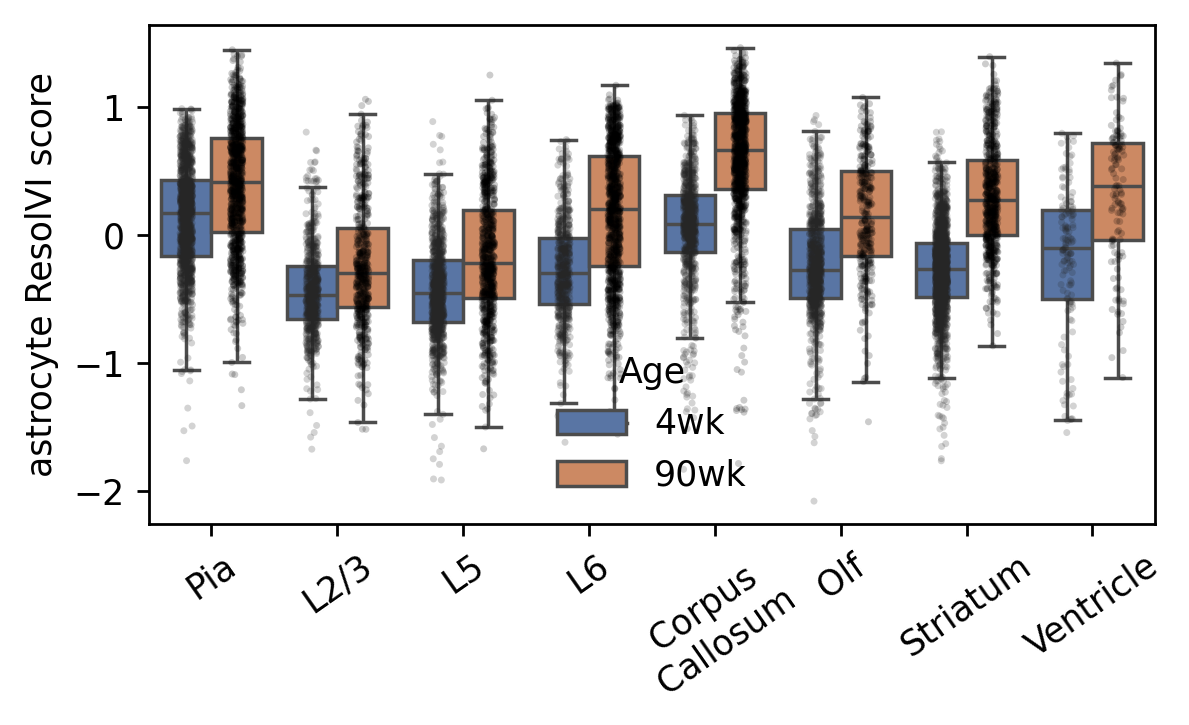

/tmp/ipykernel_3674961/3168844463.py:14: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


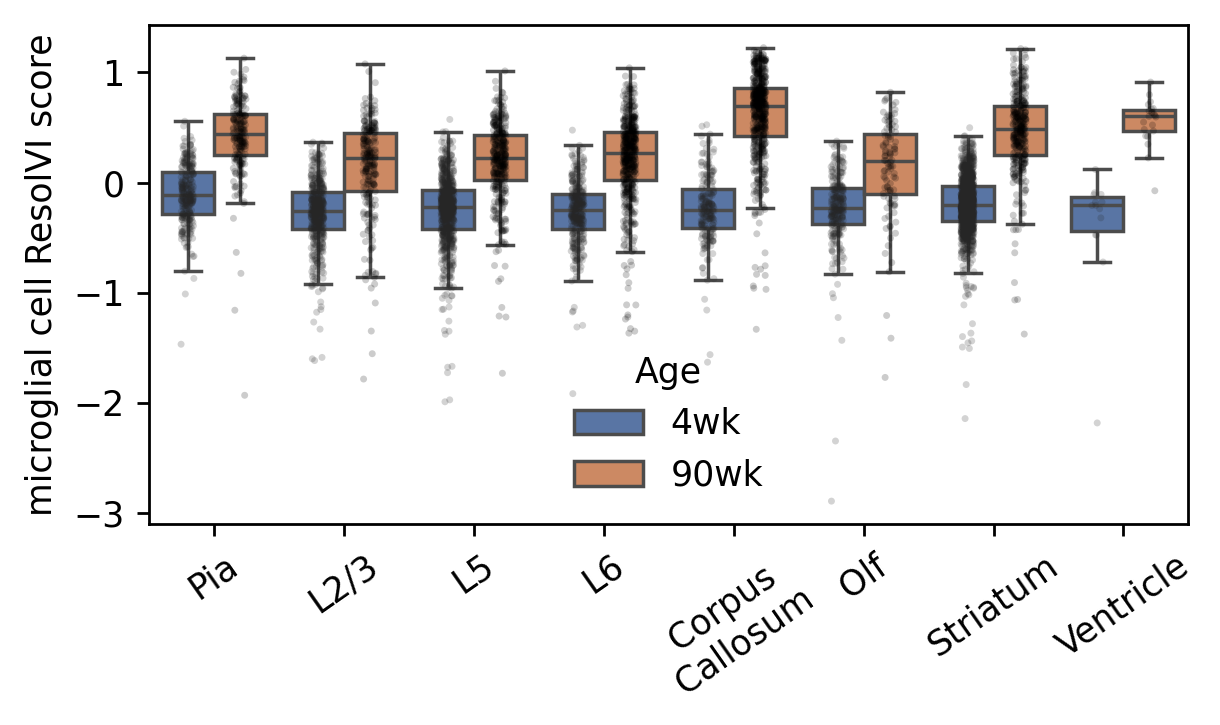

/tmp/ipykernel_3674961/3168844463.py:14: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


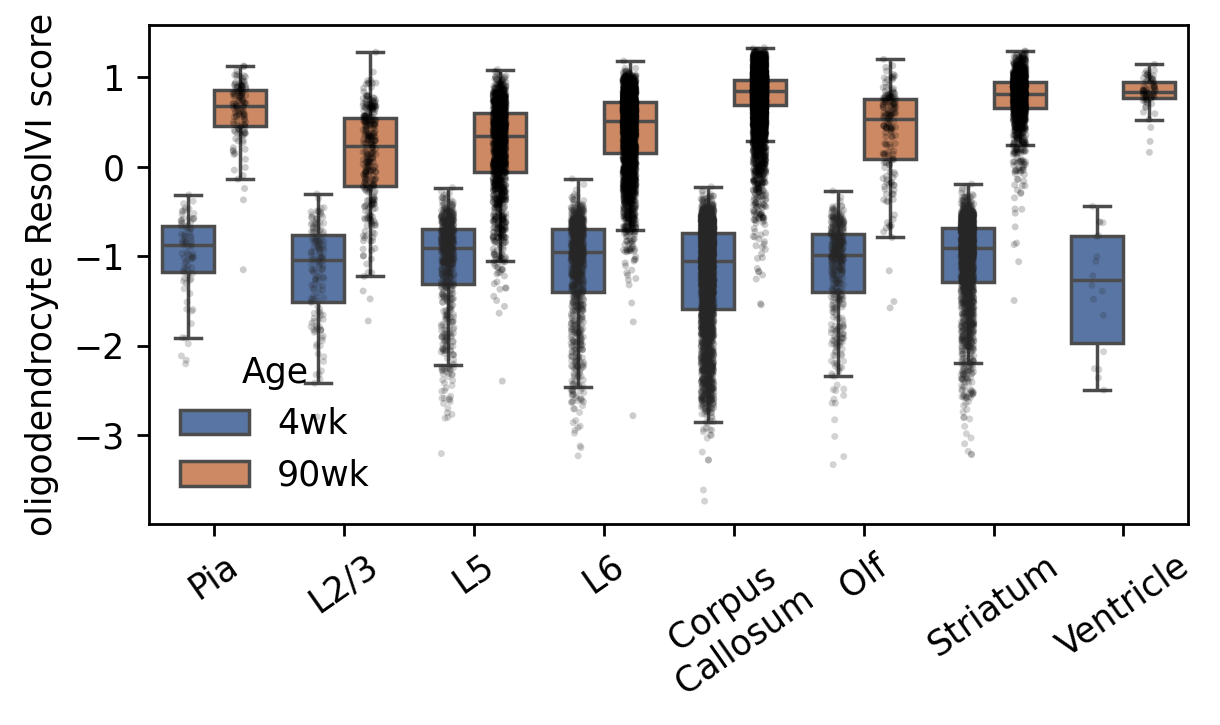

In [36]:
resolvi_age_order = [age for age in age_order if age in resolvi_cell_scores['age'].dropna().unique()]
resolvi_age_palette = dict(zip(
    resolvi_age_order,
    sns.color_palette('deep', n_colors=len(resolvi_age_order)),
))
for cell_type in cell_types:
    subset = resolvi_cell_scores.loc[resolvi_cell_scores['cell_type'].eq(cell_type)]
    fig, ax = plt.subplots(figsize=(5, 3), dpi=250)
    sns.boxplot(
        data=subset, x='tissue_short', y='score', hue='age',
        hue_order=resolvi_age_order, palette=resolvi_age_palette,
        showfliers=False, order=tissue_order, ax=ax,
    )
    sns.stripplot(
        data=subset, x='tissue_short', y='score', hue='age',
        hue_order=resolvi_age_order, color='black', dodge=True,
        alpha=0.2, s=2, legend=False, order=tissue_order, ax=ax,
    )
    ax.set_ylabel(f'{cell_type} ResolVI score')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=35)
    ax.legend(title='Age', frameon=False)
    fig.tight_layout()
    plt.show()


### Activation score versus proximity to neighboring cell types

For each astrocyte or microglial cell, the nearest VLMC, endothelial cell, or oligodendrocyte was found within 80 µm in the same slice. Each point contributes its cleaned-expression activation score at that nearest-neighbor distance. Curves show the mean score in a 30 µm sliding window stepped by 1 µm; each curve is centered by subtracting its mean across distance. Panels are separated by age; colors identify cleaning methods and line styles identify the neighboring cell type.

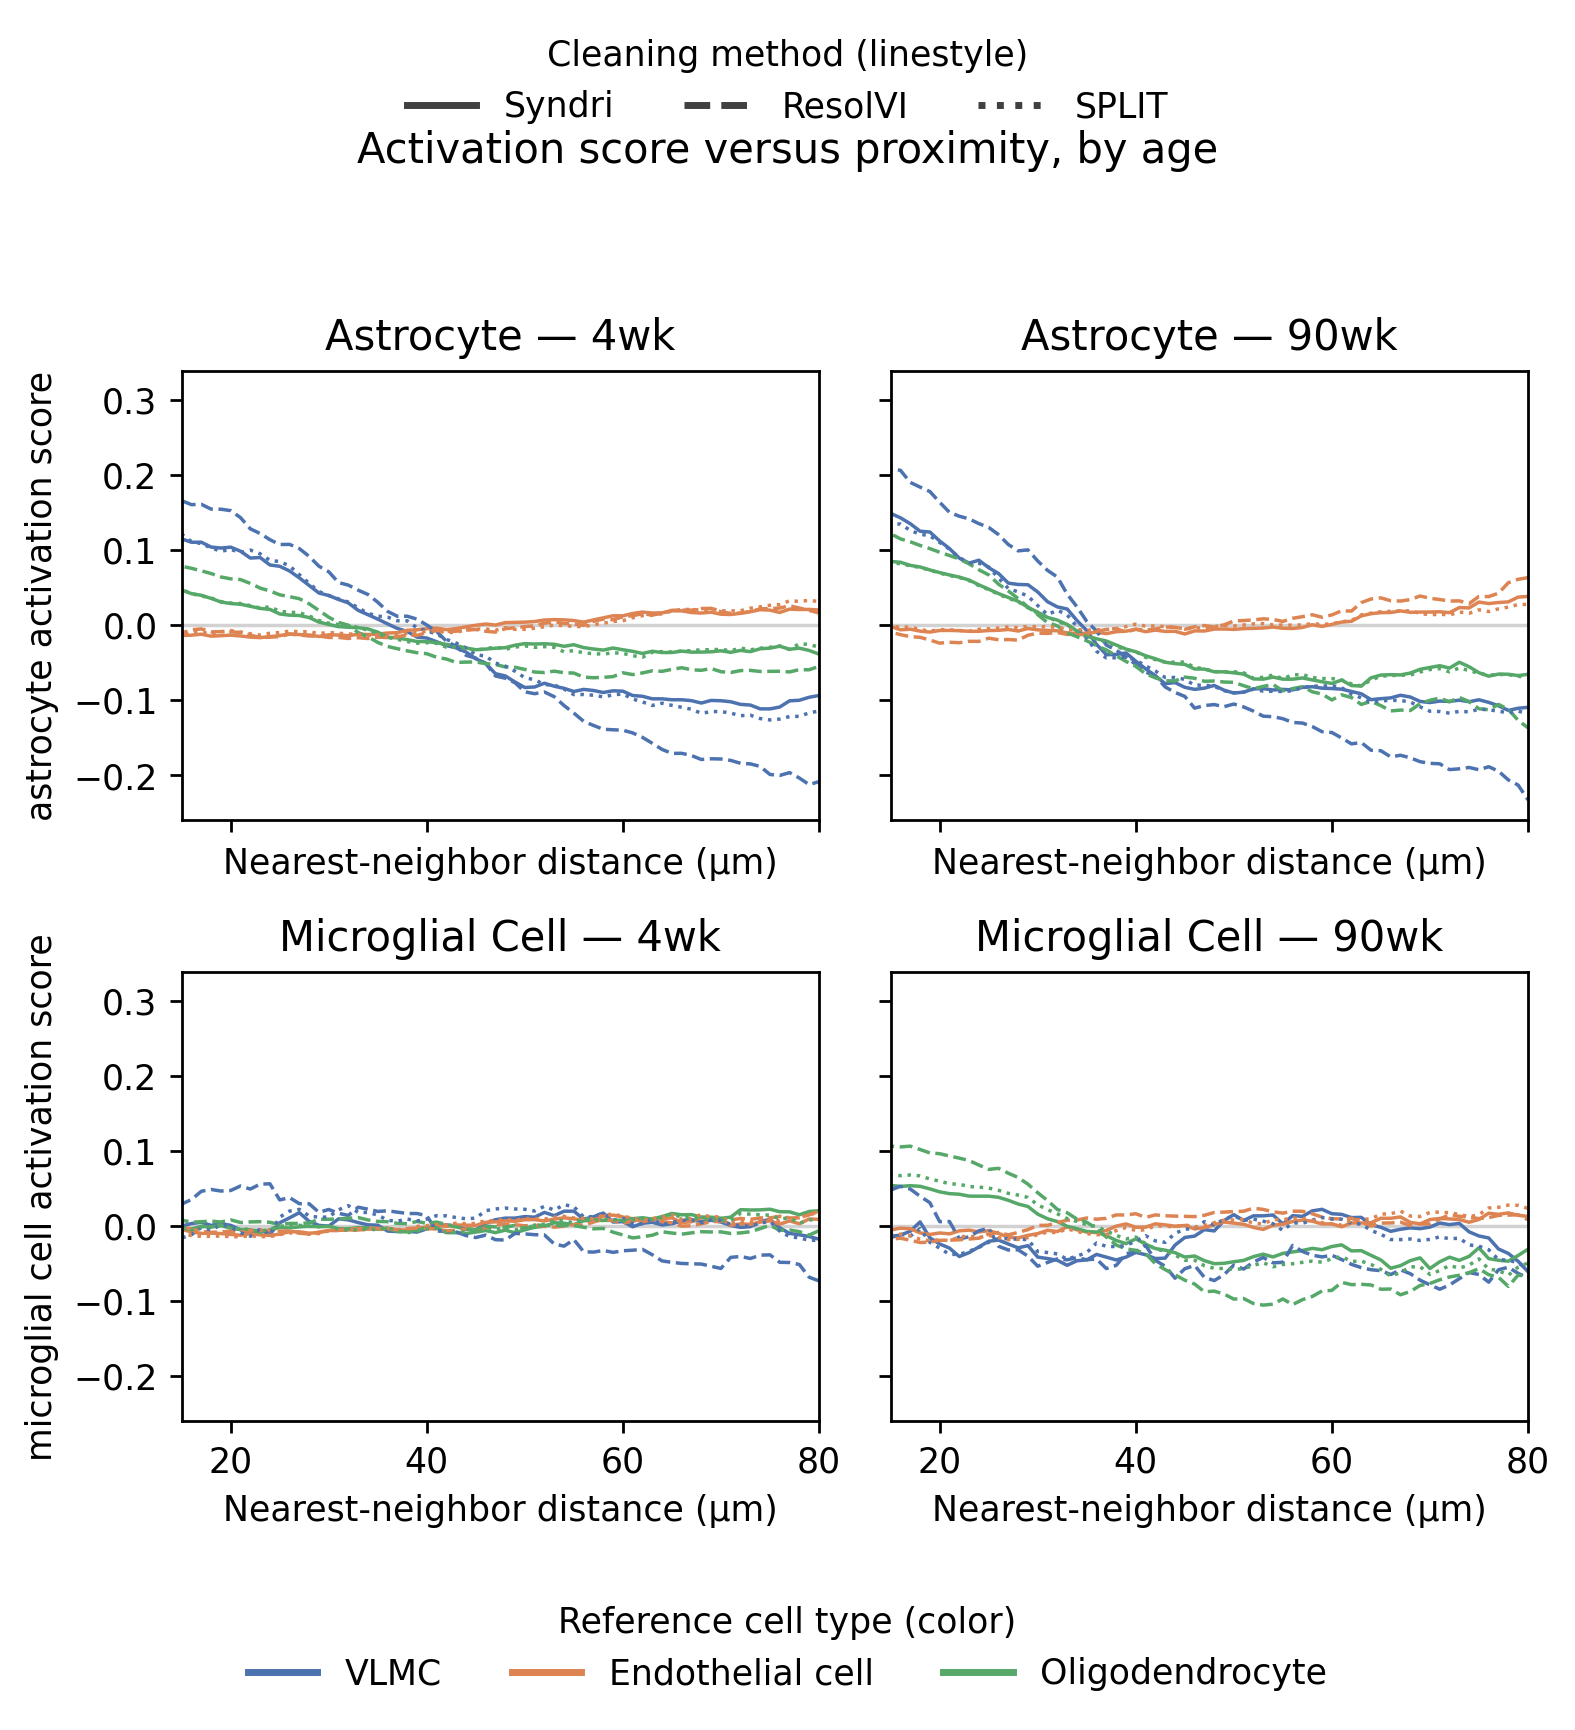

,method,age,cell_type,reference_type,distance_bins,min_window_cells,max_window_cells
0,ResolVI,4wk,astrocyte,endothelial cell,81,440,3515
1,ResolVI,4wk,astrocyte,oligodendrocyte,81,551,2603
2,ResolVI,4wk,astrocyte,vascular leptomeningeal cell,81,118,717
3,ResolVI,4wk,microglial cell,endothelial cell,81,282,1706
4,ResolVI,4wk,microglial cell,oligodendrocyte,81,260,1268
5,ResolVI,4wk,microglial cell,vascular leptomeningeal cell,81,20,286
6,ResolVI,90wk,astrocyte,endothelial cell,81,341,2689
7,ResolVI,90wk,astrocyte,oligodendrocyte,81,318,3265
8,ResolVI,90wk,astrocyte,vascular leptomeningeal cell,81,54,530
9,ResolVI,90wk,microglial cell,endothelial cell,81,154,962


In [37]:
from scipy.spatial import cKDTree

proximity_targets = ['astrocyte', 'microglial cell']
proximity_references = ['vascular leptomeningeal cell', 'endothelial cell', 'oligodendrocyte']
reference_labels = {
    'vascular leptomeningeal cell': 'VLMC',
    'endothelial cell': 'Endothelial cell',
    'oligodendrocyte': 'Oligodendrocyte',
}
distance_limit_um = 80.0
distance_centers = np.arange(0.0, distance_limit_um + 1.0, 1.0)
half_window_um = 15.0

# Match each cell to the nearest reference cell in the same method and slice.
nearest_rows = []
for (method, slice_id, target_type), target_group in proximity_scores.loc[
    proximity_scores['cell_type'].isin(proximity_targets)
].groupby(['method', 'slice', 'cell_type'], observed=True, sort=False):
    target_xy = target_group[['center_x', 'center_y']].to_numpy(dtype=float)
    for reference_type in proximity_references:
        ref_group = proximity_reference_cells.loc[
            proximity_reference_cells['method'].eq(method)
            & proximity_reference_cells['slice'].eq(slice_id)
            & proximity_reference_cells['cell_type'].eq(reference_type)
        ]
        if ref_group.empty:
            continue
        ref_xy = ref_group[['center_x', 'center_y']].to_numpy(dtype=float)
        distances, nearest_idx = cKDTree(ref_xy).query(
            target_xy, k=1, distance_upper_bound=distance_limit_um
        )
        valid = np.isfinite(distances) & (nearest_idx < len(ref_group))
        if not valid.any():
            continue
        matched = target_group.iloc[np.flatnonzero(valid)][['method', 'slice', 'age', 'cell_type', 'score']].copy()
        matched['reference_type'] = reference_type
        matched['distance_um'] = distances[valid]
        nearest_rows.append(matched)

if not nearest_rows:
    raise ValueError('No target cells had a reference cell within 80 µm; check centroid coordinates and cell-type labels.')
nearest_proximity = pd.concat(nearest_rows, ignore_index=True)

# A 30 µm window is centered at each 1 µm distance step; at 0 and 80 µm
# the window is clipped to the measured 0–80 µm range.
proximity_curve_rows = []
for keys, group in nearest_proximity.groupby(
    ['method', 'age', 'cell_type', 'reference_type'], observed=True, sort=False
):
    method, age, target_type, reference_type = keys
    for center in distance_centers:
        in_window = group['distance_um'].between(
            max(0.0, center - half_window_um), min(distance_limit_um, center + half_window_um), inclusive='left'
        )
        window_scores = group.loc[in_window, 'score']
        proximity_curve_rows.append({
            'method': method, 'age': age, 'cell_type': target_type,
            'reference_type': reference_type, 'distance_um': center,
            'mean_score': window_scores.mean(), 'n_cells': int(window_scores.size),
        })
proximity_curves = pd.DataFrame(proximity_curve_rows)
proximity_curves['centered_score'] = proximity_curves['mean_score'] - proximity_curves.groupby(
    ['method', 'age', 'cell_type', 'reference_type'], observed=True
)['mean_score'].transform('mean')

reference_palette = dict(zip(
    proximity_references, sns.color_palette('deep', n_colors=len(proximity_references))
))
method_linestyles = {'Syndri': '-', 'ResolVI': '--', 'SPLIT': ':'}
proximity_age_order = [age for age in age_order if age in proximity_curves['age'].dropna().unique()]
reference_linestyles = {
    'vascular leptomeningeal cell': '-',
    'endothelial cell': '--',
    'oligodendrocyte': ':',
}
fig, axes = plt.subplots(
    2, len(proximity_age_order),
    figsize=(3.2 * len(proximity_age_order), 7), dpi=250,
    sharex=True, sharey=True, squeeze=False,
)
for row, target_type in enumerate(proximity_targets):
    for col, age in enumerate(proximity_age_order):
        ax = axes[row, col]
        plot_data = proximity_curves.loc[
            proximity_curves['cell_type'].eq(target_type)
            & proximity_curves['age'].eq(age)
        ]
        for (method, reference_type), line_data in plot_data.groupby(
            ['method', 'reference_type'], observed=True, sort=False
        ):
            line_data = line_data.sort_values('distance_um')
            ax.plot(
                line_data['distance_um'], line_data['centered_score'],
                color=reference_palette[reference_type],
                linestyle=method_linestyles[method], linewidth=1.0,
            )
        ax.axhline(0, color='gray', alpha=0.35, linewidth=1.0, linestyle='-', zorder=0)
        ax.set_title(f'{target_type.title()} — {age}')
        ax.set_xlim(15, distance_limit_um)
        ax.set_xlabel('Nearest-neighbor distance (µm)')
        ax.set_ylabel(f'{target_type} activation score' if col == 0 else '')

method_handles = [
    plt.Line2D([0], [0], color='0.25', lw=2, linestyle=method_linestyles[m], label=m)
    for m in method_order
]
reference_handles = [
    plt.Line2D([0], [0], color=reference_palette[r], lw=2, label=reference_labels[r])
    for r in proximity_references
]
fig.legend(handles=method_handles, title='Cleaning method (linestyle)', loc='upper center',
           bbox_to_anchor=(0.5, 0.99), ncol=len(method_order), frameon=False)
fig.legend(handles=reference_handles, title='Reference cell type (color)', loc='lower center',
           bbox_to_anchor=(0.5, 0.01), ncol=len(proximity_references), frameon=False)
fig.suptitle('Activation score versus proximity, by age', y=0.92)
fig.tight_layout(rect=[0, 0.10, 1, 0.88])
plt.show()

display(
    proximity_curves.groupby(['method', 'age', 'cell_type', 'reference_type'], observed=True)
    .agg(distance_bins=('distance_um', 'size'), min_window_cells=('n_cells', 'min'), max_window_cells=('n_cells', 'max'))
    .reset_index()
)

### Corpus-callosum neighborhood-score correlations by cleaning method

For each cleaning method, these panels correlate each corpus-callosum target cell's activation score with the mean score of nearby cells within 30 µm in the same slice. Oligodendrocyte scores use the inflammation gene set in the gene map (C4b, Il33, Il18). The comparisons are microglia versus nearby oligodendrocytes, astrocytes versus nearby oligodendrocytes, and astrocytes versus nearby microglia.

Set `CORRELATION_AGE_MODE` in the next cell:
- `'by_age'` (default): separate Pearson R values and KDE contours for each age, overlaid with age-specific colors.
- `'pooled'`: one Pearson R and KDE per method/comparison, using cell pairs from all ages together. Neighbors are still matched within their original slices.

`correlation_summary` records the selected mode and sample sizes. Pooling weights cells equally, so ages/slices with more cells contribute more. A pooled correlation can reflect between-age score differences even when within-age correlations are weak. These are descriptive cell-level correlations; cells with overlapping neighborhoods are not independent replicates.


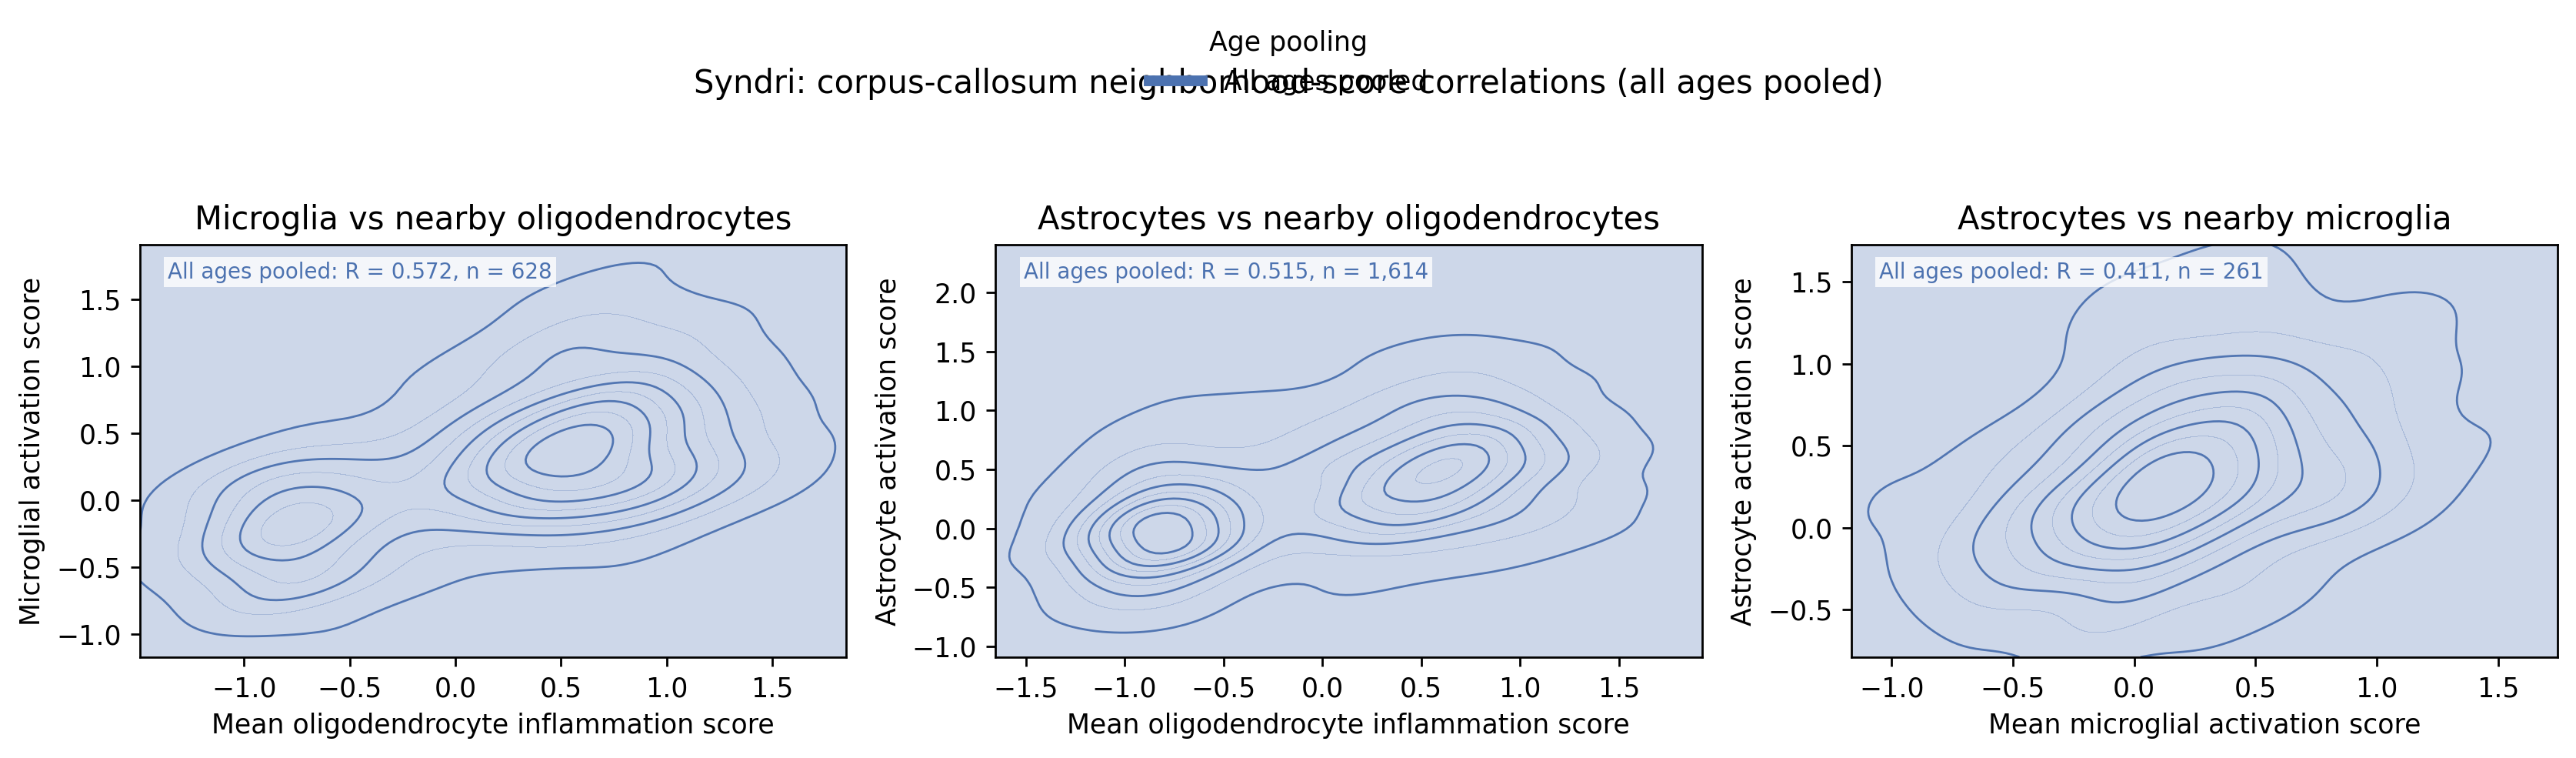

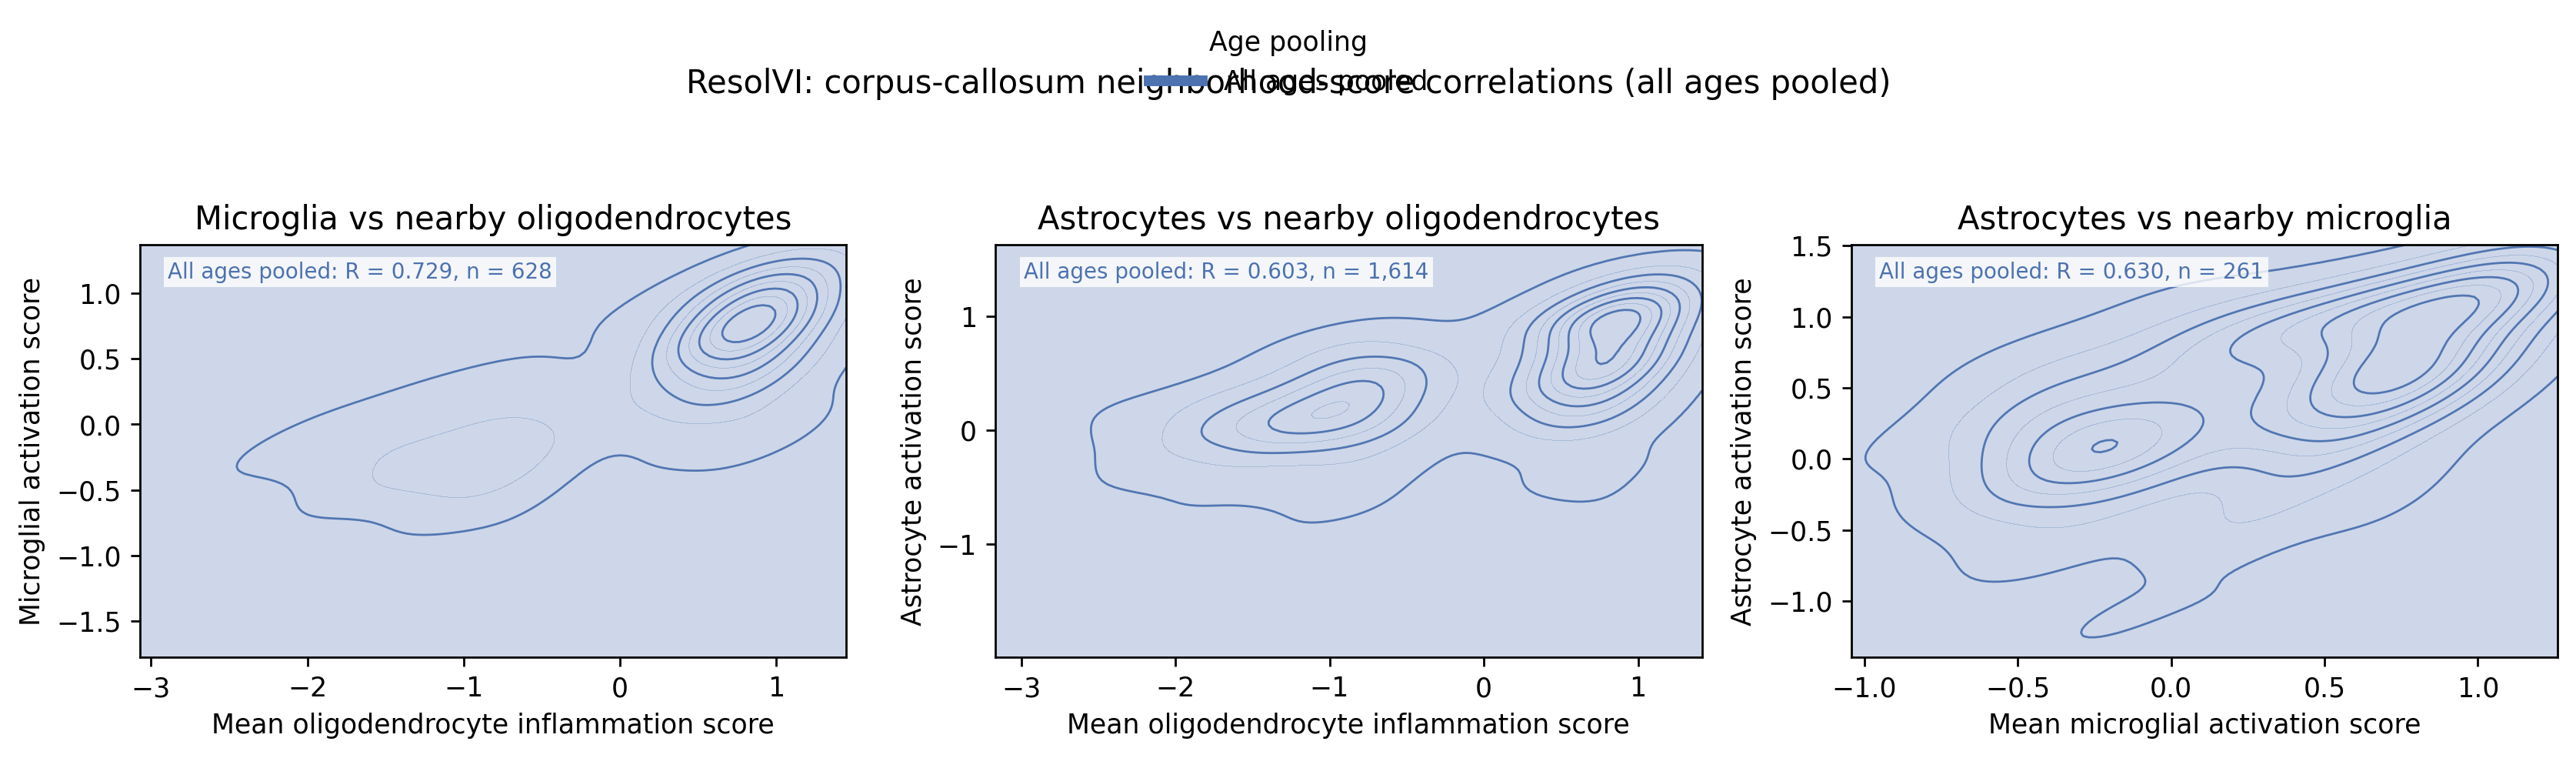

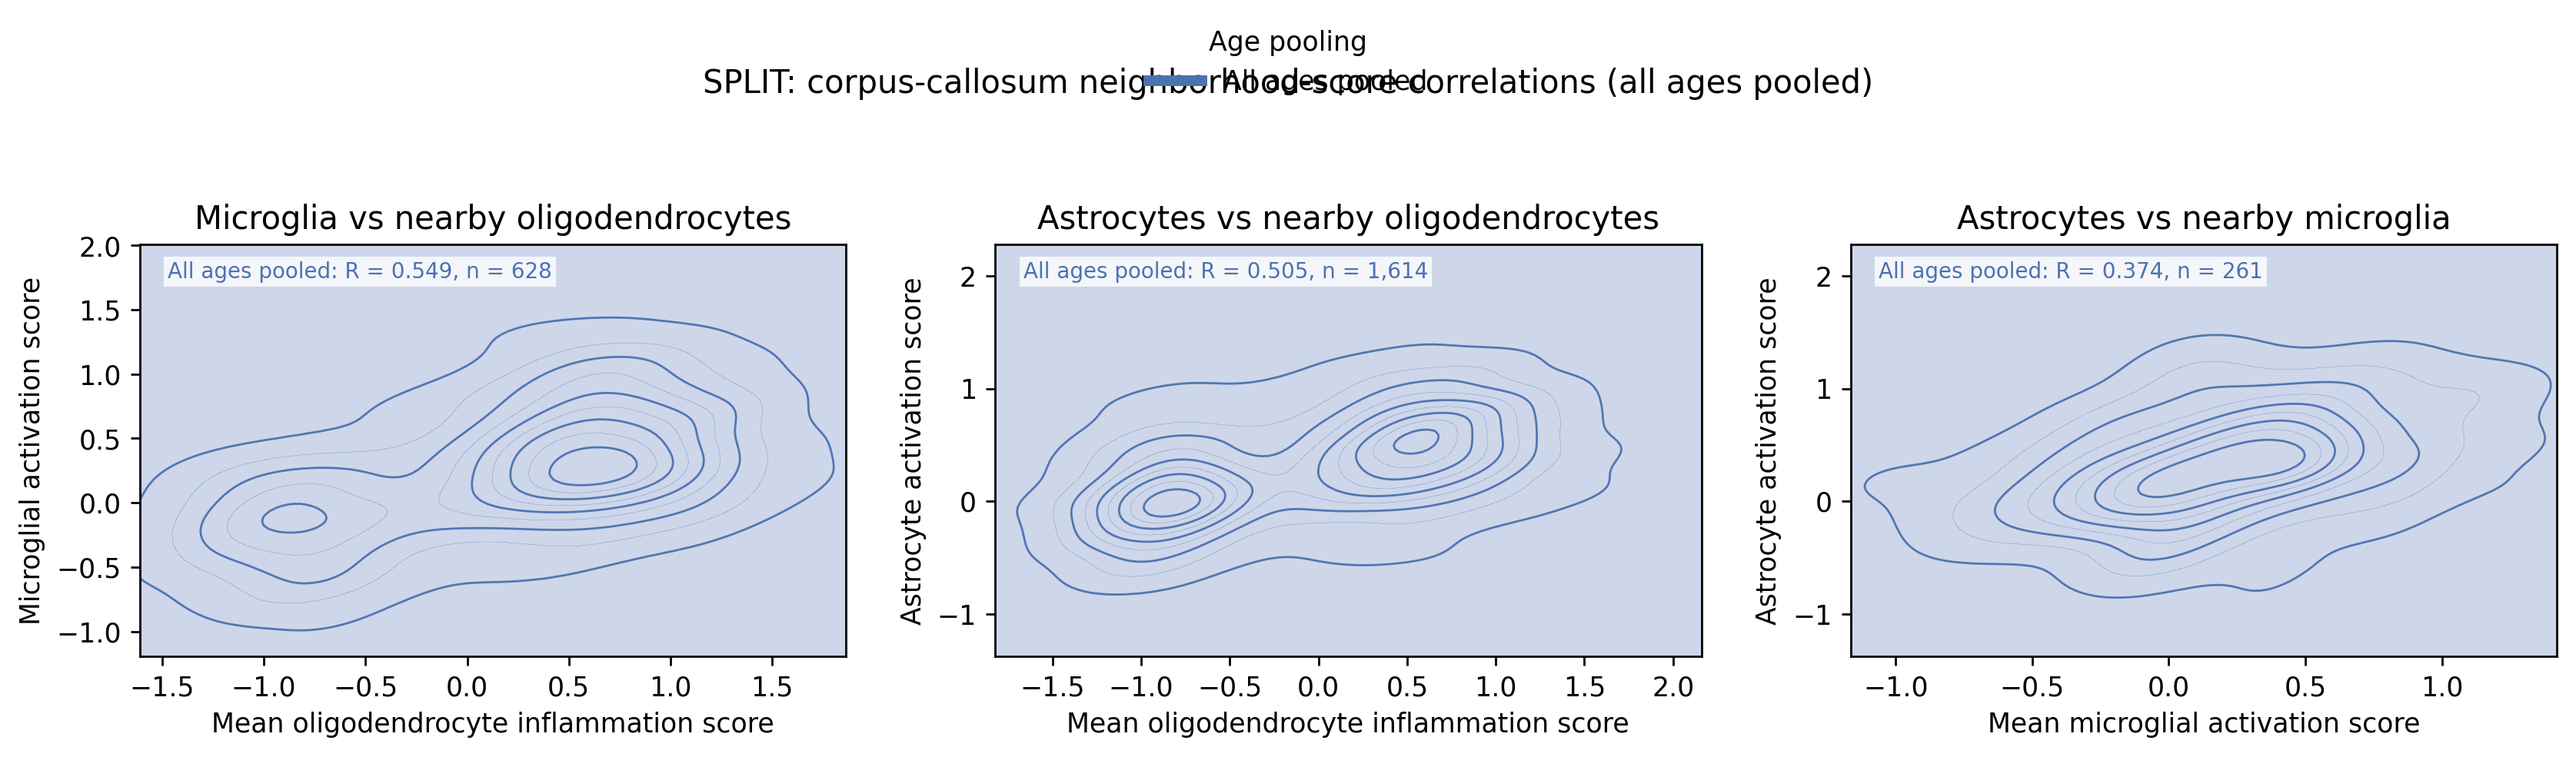

,method,comparison,age,age_mode,pearson_r,n_cells
0,Syndri,Microglia vs nearby oligodendrocytes,All ages pooled,pooled,0.572197,628
1,Syndri,Astrocytes vs nearby oligodendrocytes,All ages pooled,pooled,0.514558,1614
2,Syndri,Astrocytes vs nearby microglia,All ages pooled,pooled,0.410677,261
3,ResolVI,Microglia vs nearby oligodendrocytes,All ages pooled,pooled,0.729284,628
4,ResolVI,Astrocytes vs nearby oligodendrocytes,All ages pooled,pooled,0.603246,1614
5,ResolVI,Astrocytes vs nearby microglia,All ages pooled,pooled,0.630142,261
6,SPLIT,Microglia vs nearby oligodendrocytes,All ages pooled,pooled,0.549053,628
7,SPLIT,Astrocytes vs nearby oligodendrocytes,All ages pooled,pooled,0.505383,1614
8,SPLIT,Astrocytes vs nearby microglia,All ages pooled,pooled,0.374284,261


In [38]:
from scipy.stats import gaussian_kde, pearsonr

CORRELATION_AGE_MODE = 'pooled'  # 'by_age' or 'pooled'
if CORRELATION_AGE_MODE not in {'by_age', 'pooled'}:
    raise ValueError("CORRELATION_AGE_MODE must be 'by_age' or 'pooled'")

correlation_specs = [
    {
        'name': 'Microglia vs nearby oligodendrocytes',
        'target_type': 'microglial cell', 'neighbor_type': 'oligodendrocyte',
        'x_label': 'Microglial activation score',
        'y_label': 'Mean oligodendrocyte inflammation score',
    },
    {
        'name': 'Astrocytes vs nearby oligodendrocytes',
        'target_type': 'astrocyte', 'neighbor_type': 'oligodendrocyte',
        'x_label': 'Astrocyte activation score',
        'y_label': 'Mean oligodendrocyte inflammation score',
    },
    {
        'name': 'Astrocytes vs nearby microglia',
        'target_type': 'astrocyte', 'neighbor_type': 'microglial cell',
        'x_label': 'Astrocyte activation score',
        'y_label': 'Mean microglial activation score',
    },
]
correlation_rows = []
corpus_callosum_label = 'Corpus\nCallosum'
for method in method_order:
    method_data = proximity_scores.loc[
        proximity_scores['method'].eq(method)
        & proximity_scores['tissue_short'].eq(corpus_callosum_label)
    ]
    for slice_id, slice_data in method_data.groupby('slice', observed=True, sort=False):
        for spec in correlation_specs:
            targets = slice_data.loc[slice_data['cell_type'].eq(spec['target_type'])]
            neighbors = slice_data.loc[slice_data['cell_type'].eq(spec['neighbor_type'])]
            if targets.empty or neighbors.empty:
                continue
            target_xy = targets[['center_x', 'center_y']].to_numpy(dtype=float)
            neighbor_xy = neighbors[['center_x', 'center_y']].to_numpy(dtype=float)
            neighbor_lists = cKDTree(neighbor_xy).query_ball_point(target_xy, r=30.0)
            neighbor_scores = neighbors['score'].to_numpy(dtype=float)
            for target_idx, neighbor_idx in enumerate(neighbor_lists):
                if not neighbor_idx:
                    continue
                target = targets.iloc[target_idx]
                correlation_rows.append({
                    'method': method, 'slice': slice_id, 'age': target['age'],
                    'comparison': spec['name'], 'target_score': float(target['score']),
                    'neighbor_mean_score': float(neighbor_scores[neighbor_idx].mean()),
                    'n_neighbors': len(neighbor_idx),
                })

correlation_data = pd.DataFrame(correlation_rows)
if correlation_data.empty:
    raise ValueError('No corpus-callosum target cells had same-slice neighbors within 30 µm.')

correlation_age_order = [age for age in age_order if age in correlation_data['age'].dropna().unique()]
correlation_groups = correlation_age_order if CORRELATION_AGE_MODE == 'by_age' else ['All ages pooled']
age_palette = dict(zip(correlation_groups, sns.color_palette('deep', n_colors=len(correlation_groups))))
correlation_summary_rows = []
for method in method_order:
    fig, axes = plt.subplots(1, 3, figsize=(13.5, 4), dpi=250)
    for ax, spec in zip(axes, correlation_specs):
        plot_data = correlation_data.loc[
            correlation_data['method'].eq(method)
            & correlation_data['comparison'].eq(spec['name'])
        ]
        all_x = plot_data['neighbor_mean_score'].to_numpy(dtype=float)
        all_y = plot_data['target_score'].to_numpy(dtype=float)
        if len(plot_data):
            x_pad = max((np.nanmax(all_x) - np.nanmin(all_x)) * 0.05, 1e-6)
            y_pad = max((np.nanmax(all_y) - np.nanmin(all_y)) * 0.05, 1e-6)
            x_grid = np.linspace(np.nanmin(all_x) - x_pad, np.nanmax(all_x) + x_pad, 120)
            y_grid = np.linspace(np.nanmin(all_y) - y_pad, np.nanmax(all_y) + y_pad, 120)
            xx, yy = np.meshgrid(x_grid, y_grid)
        for age_idx, age in enumerate(correlation_groups):
            # Pool individual cell pairs, rather than averaging age-specific correlations or KDEs.
            age_data = plot_data.loc[plot_data['age'].eq(age)] if CORRELATION_AGE_MODE == 'by_age' else plot_data
            age_data = age_data.loc[
                np.isfinite(age_data['neighbor_mean_score']) & np.isfinite(age_data['target_score'])
            ]
            x = age_data['neighbor_mean_score'].to_numpy(dtype=float)
            y = age_data['target_score'].to_numpy(dtype=float)
            enough_variation = len(age_data) >= 2 and np.unique(x).size > 1 and np.unique(y).size > 1
            r_value = float(pearsonr(x, y)[0]) if enough_variation else np.nan
            if enough_variation:
                try:
                    density = gaussian_kde(np.vstack([x, y]))(
                        np.vstack([xx.ravel(), yy.ravel()])
                    ).reshape(xx.shape)
                    density_levels = np.linspace(density.max() * 0.04, density.max(), 10)
                    age_color = age_palette[age]
                    ax.contourf(xx, yy, density, levels=density_levels,
                                colors=[age_color], alpha=0.28, extend='min')
                    ax.contour(xx, yy, density, levels=density_levels[::2],
                               colors=[age_color], linewidths=0.8, alpha=0.95)
                except (np.linalg.LinAlgError, ValueError):
                    pass
            ax.text(0.04, 0.96 - age_idx * 0.11,
                    f'{age}: R = {r_value:.3f}, n = {len(age_data):,}',
                    color=age_palette[age], transform=ax.transAxes,
                    ha='left', va='top', fontsize=8,
                    bbox={'facecolor': 'white', 'alpha': 0.8, 'edgecolor': 'none', 'pad': 1.5})
            correlation_summary_rows.append({
                'method': method, 'comparison': spec['name'], 'age': age,
                'age_mode': CORRELATION_AGE_MODE,
                'pearson_r': r_value, 'n_cells': len(age_data),
            })
        ax.set_title(spec['name'])
        ax.set_xlabel(spec['y_label'])
        ax.set_ylabel(spec['x_label'])
    age_handles = [
        plt.Line2D([0], [0], color=age_palette[age], lw=4, label=str(age))
        for age in correlation_groups
    ]
    fig.legend(handles=age_handles, title='Age' if CORRELATION_AGE_MODE == 'by_age' else 'Age pooling', loc='upper center',
               bbox_to_anchor=(0.5, 0.99), ncol=max(1, len(correlation_groups)), frameon=False)
    mode_title = 'by age' if CORRELATION_AGE_MODE == 'by_age' else 'all ages pooled'
    fig.suptitle(f'{method}: corpus-callosum neighborhood-score correlations ({mode_title})', y=0.91)
    fig.tight_layout(rect=[0, 0, 1, 0.85])
    plt.show()

correlation_summary = pd.DataFrame(correlation_summary_rows)
display(correlation_summary)


### Region- and age-specific activation-score variance by method

For each method, cell type, region, and age, bars show the sample variance pooled across the same cells used in the score boxplots. The summary table also reports the mean of the within-slice variances. These differ when slice means vary, which can explain why the earlier slice-averaged bars did not visually match pooled score distributions. Oligodendrocyte scores use the inflammation gene set; astrocyte and microglial scores use their activation gene sets.


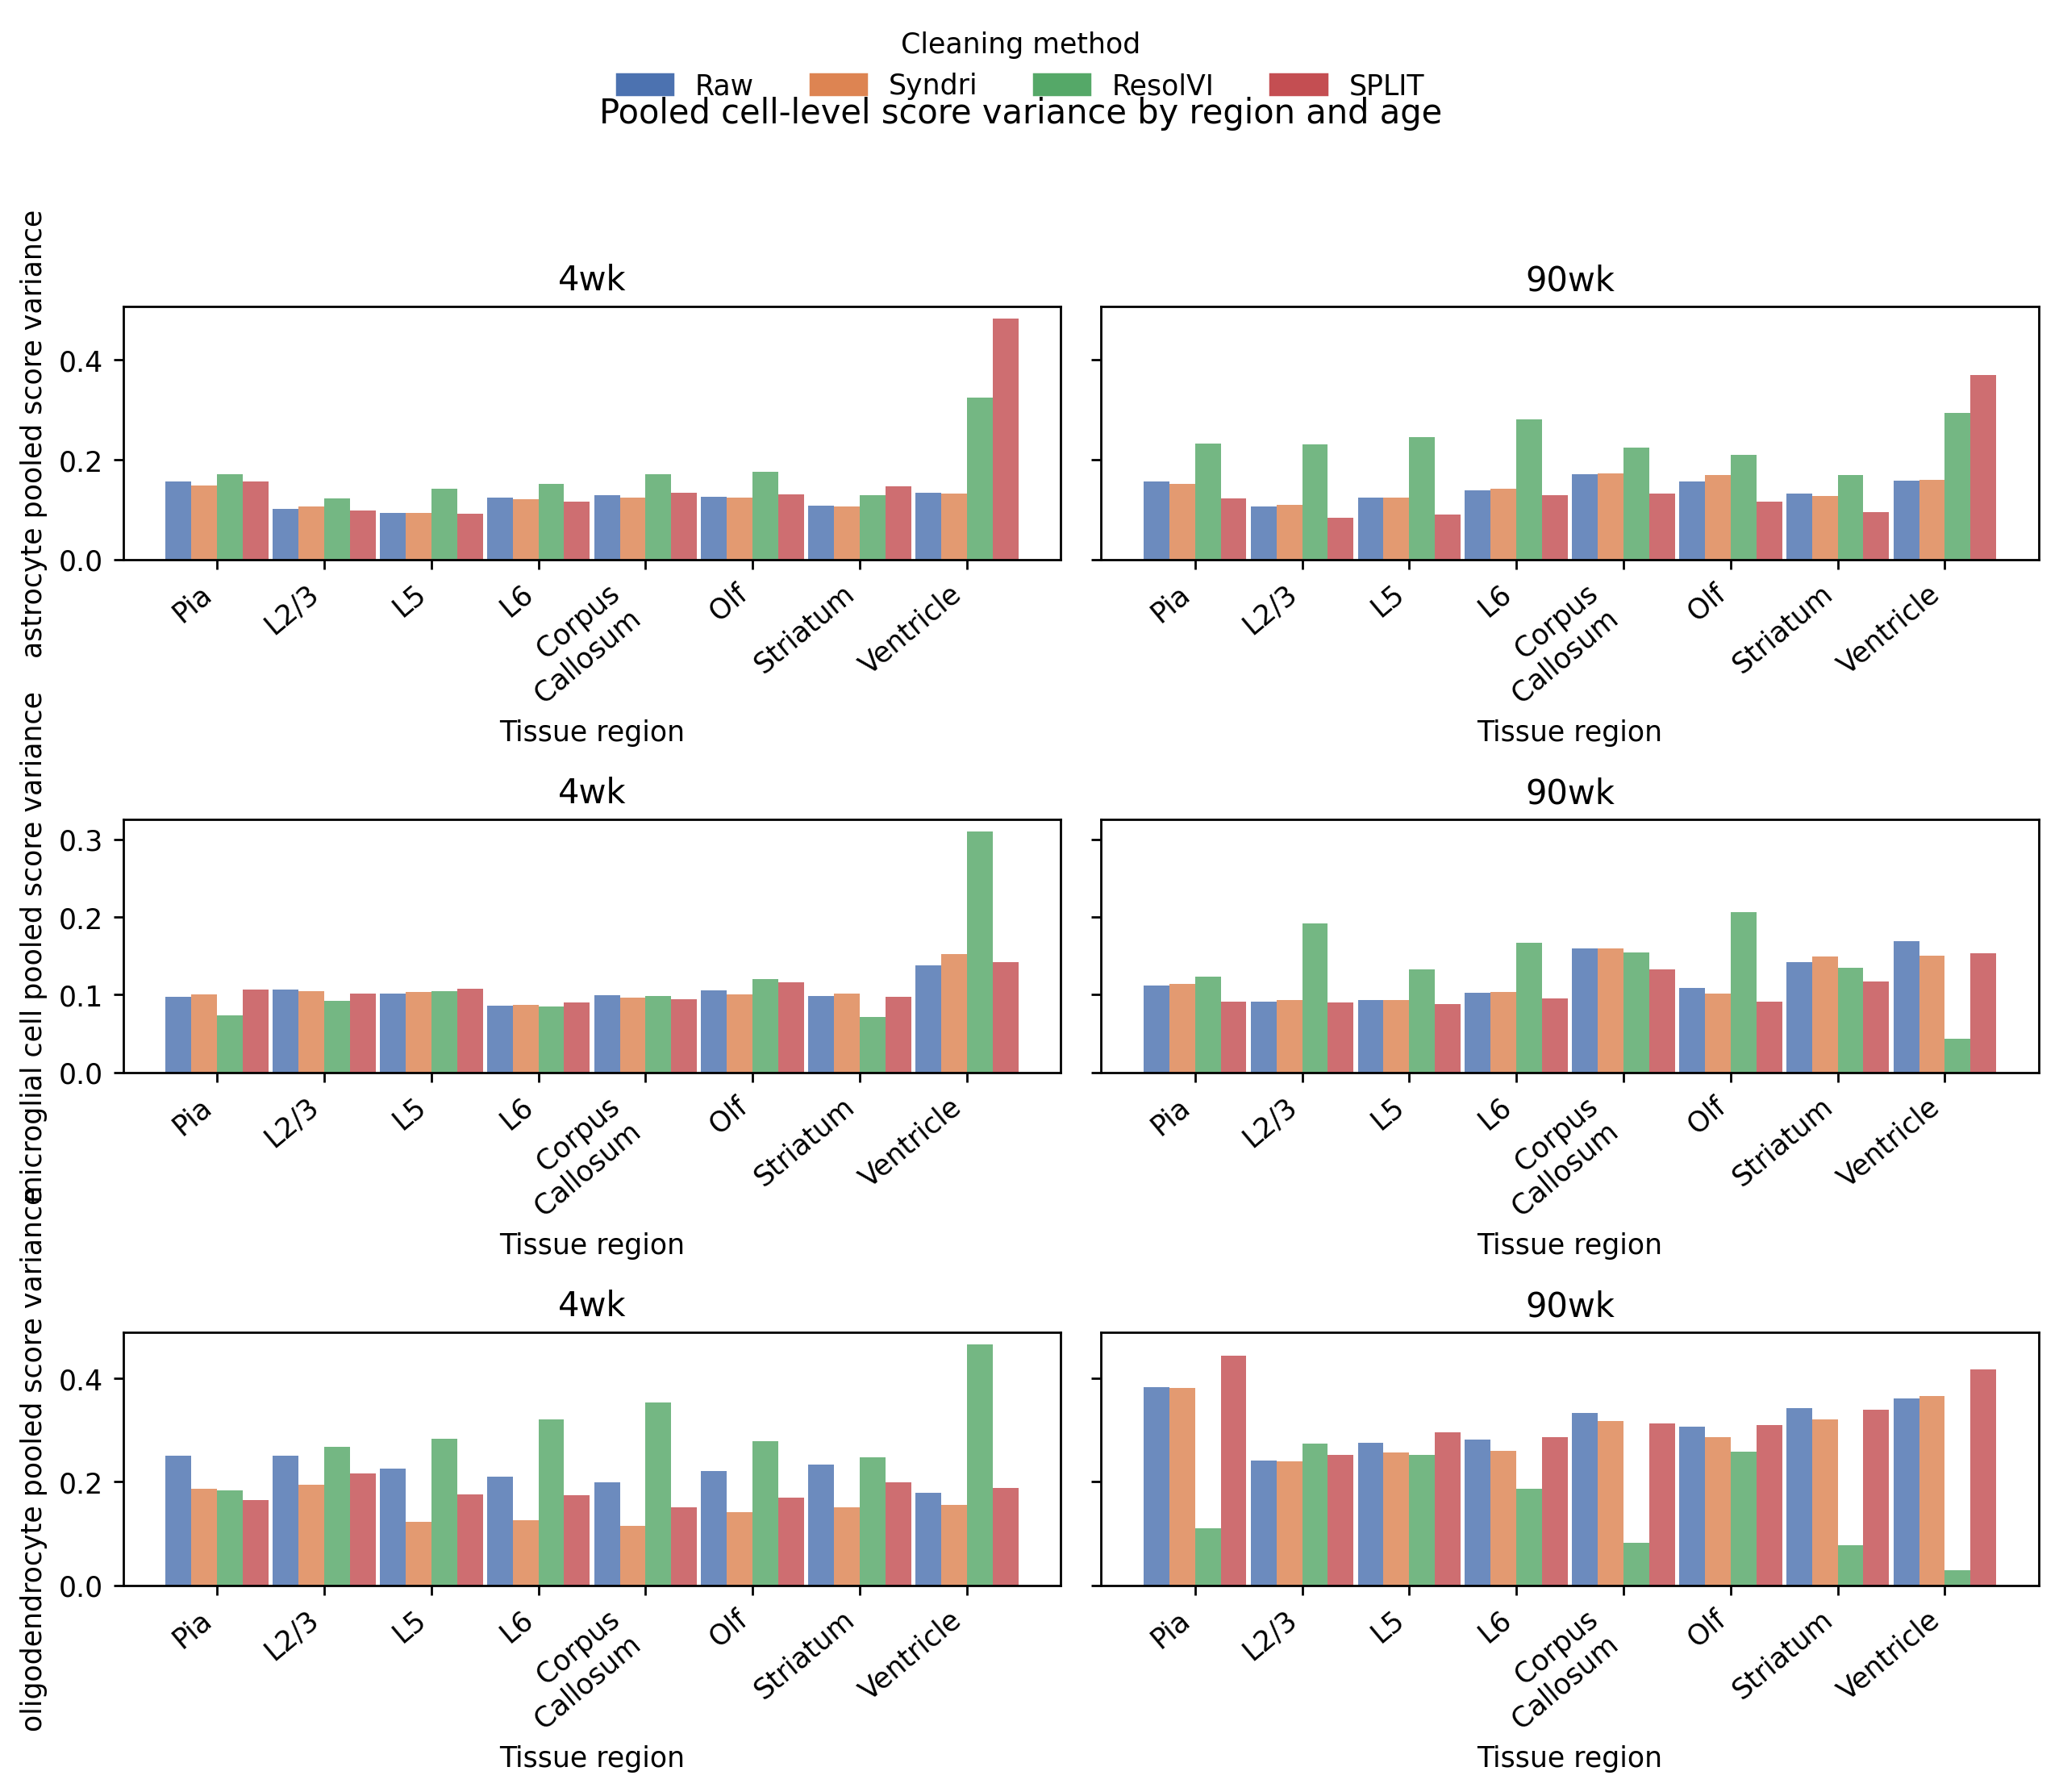

,method,age,tissue_short,cell_type,pooled_variance,n_cells,mean_within_slice_variance,sd_within_slice_variance,n_slices
0,Raw,4wk,Corpus\nCallosum,astrocyte,0.128703,817,0.117532,0.021088,6
1,ResolVI,4wk,Corpus\nCallosum,astrocyte,0.171538,817,0.145991,0.060522,6
2,SPLIT,4wk,Corpus\nCallosum,astrocyte,0.133990,817,0.125094,0.034373,6
3,Syndri,4wk,Corpus\nCallosum,astrocyte,0.124618,817,0.115567,0.018824,6
4,Raw,4wk,Pia,astrocyte,0.156886,1355,0.146600,0.024461,6
...,...,...,...,...,...,...,...,...,...
187,Syndri,90wk,L6,oligodendrocyte,0.260348,3080,0.253050,0.030832,6
188,Raw,90wk,L2/3,oligodendrocyte,0.241028,316,0.211019,0.095389,6
189,ResolVI,90wk,L2/3,oligodendrocyte,0.273776,316,0.279148,0.049468,6
190,SPLIT,90wk,L2/3,oligodendrocyte,0.252108,316,0.214860,0.129752,6


In [39]:
pooled_score_variance = (
    variance_scores.groupby(
        ['method', 'age', 'tissue_short', 'cell_type'], observed=True
    )['score']
    .agg(pooled_variance='var', n_cells='count')
    .reset_index()
)
within_slice_variance = (
    variance_scores.groupby(
        ['method', 'slice', 'age', 'tissue_short', 'cell_type'], observed=True
    )['score']
    .var(ddof=1)
    .rename('slice_variance')
    .reset_index()
    .dropna(subset=['slice_variance'])
)
within_slice_summary = (
    within_slice_variance.groupby(
        ['method', 'age', 'tissue_short', 'cell_type'], observed=True
    )['slice_variance']
    .agg(mean_within_slice_variance='mean', sd_within_slice_variance='std', n_slices='count')
    .reset_index()
)
variance_summary = pooled_score_variance.merge(
    within_slice_summary,
    on=['method', 'age', 'tissue_short', 'cell_type'],
    how='left',
)
variance_age_order = [age for age in age_order if age in variance_summary['age'].dropna().unique()]
variance_method_order = ['Raw'] + [method for method in method_order if method in variance_summary['method'].unique()]
variance_palette = dict(zip(
    variance_method_order, sns.color_palette('deep', n_colors=len(variance_method_order))
))

fig, axes = plt.subplots(
    len(cell_types), len(variance_age_order),
    figsize=(5.2 * len(variance_age_order), 9), dpi=250,
    sharey='row', squeeze=False,
)
bar_width = 0.24
region_positions = np.arange(len(tissue_order))
for row, cell_type in enumerate(cell_types):
    for col, age in enumerate(variance_age_order):
        ax = axes[row, col]
        panel = variance_summary.loc[
            variance_summary['cell_type'].eq(cell_type)
            & variance_summary['age'].eq(age)
        ]
        for method_idx, method in enumerate(variance_method_order):
            method_data = panel.loc[panel['method'].eq(method)]
            offset = (method_idx - (len(variance_method_order) - 1) / 2) * bar_width
            variances = method_data.set_index('tissue_short')['pooled_variance']
            heights = [variances.get(region, np.nan) for region in tissue_order]
            ax.bar(
                region_positions + offset, heights, width=bar_width,
                color=variance_palette[method], alpha=0.82, label=method,
            )
        ax.set_title(str(age))
        ax.set_xticks(region_positions)
        ax.set_xticklabels(tissue_order, rotation=40, ha='right')
        ax.set_xlabel('Tissue region')
        ax.set_ylabel(f'{cell_type} pooled score variance' if col == 0 else '')
fig.legend(
    handles=[plt.Rectangle((0, 0), 1, 1, color=variance_palette[m], label=m) for m in variance_method_order],
    title='Cleaning method', loc='upper center', bbox_to_anchor=(0.5, 0.99),
    ncol=len(variance_method_order), frameon=False,
)
fig.suptitle('Pooled cell-level score variance by region and age', y=0.94)
fig.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()

display(
    variance_summary.sort_values(
        ['cell_type', 'age', 'tissue_short', 'method']
    ).reset_index(drop=True)
)


# cell cycle inhibitors
# Cdkn2a, Cdkn1a



In [40]:
gene_panel = [
    'Cdkn2a',
    'Cdkn1a',

    #OPC markers
    'Pdgfra', 
    'Ptprz1', 
    'Cspg5'
]